In [1]:
# ==========================================
# STEP 1: DIAGNOSTIC & AUDIT CELL
# ==========================================
import os
import sys
import zipfile
import torch

print("=== 1. HARDWARE & GPU AUDIT ===")
print(f"PyTorch Version: {torch.__version__}")
gpu_available = torch.cuda.is_available()
print(f"CUDA Available: {gpu_available}")

if gpu_available:
    gpu_name = torch.cuda.get_device_name(0)
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"GPU Model: {gpu_name}")
    print(f"VRAM: {gpu_memory:.2f} GB")
else:
    print("WARNING: GPU is not detected! Enable GPU (T4 or P100) under Kaggle Settings.")

print("\n=== 2. FILE & PATH AUDIT ===")
expected_paths = {
    "zip_file": "/kaggle/input/notebooks/harissssss/rdd2022/RDD2022.zip",
    "yolov8s_pt": "/kaggle/input/notebooks/harissssss/rdd2022/yolov8s.pt",
    "yolo11n_pt": "/kaggle/input/notebooks/harissssss/rdd2022/yolo11n.pt",
    "prev_dataset": "/kaggle/working/roadguard_4class",
    "prev_yaml": "/kaggle/working/roadguard_4class/data.yaml",
    "prev_run": "/kaggle/working/roadguard_runs/yolov8s_4class_v1",
    "prev_best": "/kaggle/working/roadguard_runs/yolov8s_4class_v1/weights/best.pt"
}

for key, path in expected_paths.items():
    exists = os.path.exists(path)
    print(f"[{'FOUND' if exists else 'MISSING'}] {key}: {path}")

# Check inside dataset ZIP if available
zip_path = expected_paths["zip_file"]
if os.path.exists(zip_path):
    print("\n=== 3. ZIP CONTENT INSPECTION ===")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        file_list = zip_ref.namelist()
        print(f"Total files in ZIP: {len(file_list)}")
        print("Sample files (first 10):")
        for f in file_list[:10]:
            print(f" - {f}")
else:
    print("\nSearch for alternative RDD2022 dataset files in /kaggle/input:")
    for root, dirs, files in os.walk("/kaggle/input"):
        for file in files:
            if file.endswith(".zip") or file.endswith(".pt") or "rdd" in file.lower():
                print("Found file:", os.path.join(root, file))

=== 1. HARDWARE & GPU AUDIT ===
PyTorch Version: 2.11.0+cu128
CUDA Available: True
GPU Model: Tesla T4
VRAM: 14.56 GB

=== 2. FILE & PATH AUDIT ===
[MISSING] zip_file: /kaggle/input/notebooks/harissssss/rdd2022/RDD2022.zip
[MISSING] yolov8s_pt: /kaggle/input/notebooks/harissssss/rdd2022/yolov8s.pt
[MISSING] yolo11n_pt: /kaggle/input/notebooks/harissssss/rdd2022/yolo11n.pt
[MISSING] prev_dataset: /kaggle/working/roadguard_4class
[MISSING] prev_yaml: /kaggle/working/roadguard_4class/data.yaml
[MISSING] prev_run: /kaggle/working/roadguard_runs/yolov8s_4class_v1
[MISSING] prev_best: /kaggle/working/roadguard_runs/yolov8s_4class_v1/weights/best.pt

Search for alternative RDD2022 dataset files in /kaggle/input:


In [2]:
# ==========================================
# STEP 1.2: DYNAMIC PATH DISCOVERY & VERIFICATION
# ==========================================
import os

print("=== SEARCHING FOR ATTACHED DATASETS & WEIGHTS ===")
input_dir = "/kaggle/input"

all_files = []
for root, dirs, files in os.walk(input_dir):
    for f in files:
        full_path = os.path.join(root, f)
        all_files.append(full_path)

print(f"Total files found in /kaggle/input: {len(all_files)}")

# Filter relevant extensions and keywords
zips = [f for f in all_files if f.endswith(".zip")]
pts = [f for f in all_files if f.endswith(".pt")]
xmls = [f for f in all_files if f.endswith(".xml")]
jpgs = [f for f in all_files if f.endswith((".jpg", ".png", ".jpeg"))]

print("\n--- Zip Files Found ---")
for z in zips:
    print(z)

print("\n--- Weights (.pt) Found ---")
for p in pts:
    print(p)

print("\n--- Dataset Summary ---")
print(f"Total XML Annotations: {len(xmls)}")
print(f"Total Images: {len(jpgs)}")

if len(zips) == 0 and len(jpgs) == 0:
    print("\n[!] WARNING: No data found. Make sure you clicked '+ Add Data' in Kaggle and attached your dataset.")

=== SEARCHING FOR ATTACHED DATASETS & WEIGHTS ===
Total files found in /kaggle/input: 76770

--- Zip Files Found ---

--- Weights (.pt) Found ---

--- Dataset Summary ---
Total XML Annotations: 0
Total Images: 38385


In [4]:
# ==========================================
# STEP 2.1: ROBUST DATASET CONVERSION & INDEXING
# ==========================================
import os
import glob
import shutil
import xml.etree.ElementTree as ET
from pathlib import Path
from sklearn.model_selection import train_test_split

print("=== 1. INDEXING ALL FILES ===")
input_dir = "/kaggle/input"

# Search for image & xml files globally
xml_files = glob.glob(os.path.join(input_dir, "**/*.xml"), recursive=True)
img_files = glob.glob(os.path.join(input_dir, "**/*.jpg"), recursive=True) + \
            glob.glob(os.path.join(input_dir, "**/*.png"), recursive=True) + \
            glob.glob(os.path.join(input_dir, "**/*.jpeg"), recursive=True)

print(f"Total XML Annotation Files Found: {len(xml_files)}")
print(f"Total Image Files Found: {len(img_files)}")

# Map base names to full XML paths for O(1) fast lookup
xml_dict = {}
for x in xml_files:
    base = os.path.splitext(os.path.basename(x))[0]
    xml_dict[base] = x

CLASS_MAPPING = {
    "D00": 0,  # Longitudinal Crack
    "D10": 1,  # Transverse Crack
    "D20": 2,  # Alligator Crack
    "D40": 3   # Pothole
}

WORK_DIR = Path("/kaggle/working/roadguard_4class")
if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)

for split in ["train", "val", "test"]:
    (WORK_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (WORK_DIR / split / "labels").mkdir(parents=True, exist_ok=True)

class_counts = {k: 0 for k in CLASS_MAPPING.keys()}
unsupported_counts = {}

def parse_xml_to_yolo(xml_path):
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
        
        size = root.find("size")
        if size is None:
            return None
        
        width = float(size.find("width").text)
        height = float(size.find("height").text)
        
        if width == 0 or height == 0:
            return None

        yolo_annotations = []
        for obj in root.findall("object"):
            class_name = obj.find("name").text.strip()
            
            if class_name in CLASS_MAPPING:
                class_id = CLASS_MAPPING[class_name]
                class_counts[class_name] += 1
            else:
                unsupported_counts[class_name] = unsupported_counts.get(class_name, 0) + 1
                continue

            bndbox = obj.find("bndbox")
            xmin = float(bndbox.find("xmin").text)
            ymin = float(bndbox.find("ymin").text)
            xmax = float(bndbox.find("xmax").text)
            ymax = float(bndbox.find("ymax").text)

            x_center = ((xmin + xmax) / 2.0) / width
            y_center = ((ymin + ymax) / 2.0) / height
            bbox_width = (xmax - xmin) / width
            bbox_height = (ymax - ymin) / height

            x_center = max(0.0, min(1.0, x_center))
            y_center = max(0.0, min(1.0, y_center))
            bbox_width = max(0.0, min(1.0, bbox_width))
            bbox_height = max(0.0, min(1.0, bbox_height))

            yolo_annotations.append(f"{class_id} {x_center:.6f} {y_center:.6f} {bbox_width:.6f} {bbox_height:.6f}")

        return yolo_annotations
    except Exception as e:
        return None

print("\n=== 2. MATCHING IMAGES AND ANNOTATIONS ===")
matched_pairs = []
for img_path in img_files:
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    
    if base_name in xml_dict:
        xml_path = xml_dict[base_name]
        annotations = parse_xml_to_yolo(xml_path)
        if annotations and len(annotations) > 0:
            matched_pairs.append((img_path, annotations))

print(f"Valid image-annotation pairs matched: {len(matched_pairs)}")
print("\nClass Instance Counts:")
for cls, count in class_counts.items():
    print(f" - {cls}: {count} instances")

if unsupported_counts:
    print(f"\nOther classes ignored: {unsupported_counts}")

if len(matched_pairs) == 0:
    print("\n[!] CRITICAL: No XML annotations matched image base names.")
    print("Printing sample Image Base Names vs sample XML Base Names:")
    print("Sample Image names:", [os.path.splitext(os.path.basename(x))[0] for x in img_files[:5]])
    print("Sample XML names:", list(xml_dict.keys())[:5])
else:
    print("\n=== 3. CREATING SPLITS (80% Train, 10% Val, 10% Test) ===")
    train_pairs, temp_pairs = train_test_split(matched_pairs, test_size=0.20, random_state=42)
    val_pairs, test_pairs = train_test_split(temp_pairs, test_size=0.50, random_state=42)

    def save_split_data(split_name, pairs):
        for img_path, annotations in pairs:
            base_name = os.path.splitext(os.path.basename(img_path))[0]
            
            dst_img = WORK_DIR / split_name / "images" / os.path.basename(img_path)
            shutil.copy2(img_path, dst_img)
            
            dst_txt = WORK_DIR / split_name / "labels" / f"{base_name}.txt"
            with open(dst_txt, "w") as f:
                f.write("\n".join(annotations))

    print("Copying images and writing YOLO label files...")
    save_split_data("train", train_pairs)
    save_split_data("val", val_pairs)
    save_split_data("test", test_pairs)

    print(f" - Train samples: {len(train_pairs)}")
    print(f" - Val samples: {len(val_pairs)}")
    print(f" - Test samples: {len(test_pairs)}")

    print("\n=== 4. GENERATING DATA.YAML ===")
    data_yaml_content = f"""path: {WORK_DIR}
train: train/images
val: val/images
test: test/images

names:
  0: D00_Longitudinal
  1: D10_Transverse
  2: D20_Alligator
  3: D40_Pothole
"""
    yaml_path = WORK_DIR / "data.yaml"
    with open(yaml_path, "w") as f:
        f.write(data_yaml_content)

    print(f"data.yaml ready at: {yaml_path}")

=== 1. INDEXING ALL FILES ===
Total XML Annotation Files Found: 0
Total Image Files Found: 38385

=== 2. MATCHING IMAGES AND ANNOTATIONS ===
Valid image-annotation pairs matched: 0

Class Instance Counts:
 - D00: 0 instances
 - D10: 0 instances
 - D20: 0 instances
 - D40: 0 instances

[!] CRITICAL: No XML annotations matched image base names.
Printing sample Image Base Names vs sample XML Base Names:
Sample Image names: ['India_005117', 'United_States_001891', 'Czech_000092', 'India_009494', 'Japan_009926']
Sample XML names: []


In [5]:
# ==========================================
# STEP 1.3: ANNOTATION FORMAT DISCOVERY
# ==========================================
import os
import glob

print("=== SEARCHING FOR ANNOTATIONS (TXT, JSON, ZIP, CSV) ===")
input_dir = "/kaggle/input"

txt_files = glob.glob(os.path.join(input_dir, "**/*.txt"), recursive=True)
json_files = glob.glob(os.path.join(input_dir, "**/*.json"), recursive=True)
zip_files = glob.glob(os.path.join(input_dir, "**/*.zip"), recursive=True)

print(f"Total .txt files found: {len(txt_files)}")
print(f"Total .json files found: {len(json_files)}")
print(f"Total .zip files found: {len(zip_files)}")

if txt_files:
    print("\nSample .txt annotation files:")
    for t in txt_files[:5]:
        print(f" - {t}")
        # Print content of first text file
        with open(t, "r") as f:
            print("   Content preview:", f.readline().strip())

if zip_files:
    print("\nSample .zip files:")
    for z in zip_files:
        print(f" - {z}")

print("\nTop 10 directories inside /kaggle/input:")
for root, dirs, files in os.walk(input_dir):
    if len(files) > 0:
        print(f"Directory: {root} | Files count: {len(files)}")

=== SEARCHING FOR ANNOTATIONS (TXT, JSON, ZIP, CSV) ===
Total .txt files found: 38385
Total .json files found: 0
Total .zip files found: 0

Sample .txt annotation files:
 - /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels/Czech_001597.txt
   Content preview: 
 - /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels/China_MotorBike_001826.txt
   Content preview: 0 0.500977 0.764648 0.998047 0.259766
 - /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels/China_Drone_001527.txt
   Content preview: 2 0.125977 0.610352 0.248047 0.287109
 - /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels/Norway_002636.txt
   Content preview: 
 - /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels/Norway_004263.txt
   Content preview: 

Top 10 directories inside /kaggle/input:
Directory: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels | Files count: 5758
Directory: /kaggle/input/datasets/aliabdelmenam/rdd-2022/R

In [ ]:
# ==========================================
# STEP 2.2: PRE-SPLIT DATASET AUDIT & DATA.YAML CREATION
# ==========================================
import os
import glob

DATASET_ROOT = "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT"

print("=== 1. VERIFYING SPLIT DIRECTORIES ===")
splits = ["train", "val", "test"]
for s in splits:
    img_path = os.path.join(DATASET_ROOT, s, "images")
    lbl_path = os.path.join(DATASET_ROOT, s, "labels")
    n_imgs = len(glob.glob(os.path.join(img_path, "*"))) if os.path.exists(img_path) else 0
    n_lbls = len(glob.glob(os.path.join(lbl_path, "*"))) if os.path.exists(lbl_path) else 0
    print(f"[{s.upper()}] Images: {n_imgs} | Labels: {n_lbls}")

print("\n=== 2. AUDITING CLASS INSTANCES ACROSS TRAIN & VAL ===")
class_names = {0: "D00", 1: "D10", 2: "D20", 3: "D40"}
counts = {0: 0, 1: 0, 2: 0, 3: 0}
empty_files = 0
total_files = 0

train_val_labels = glob.glob(os.path.join(DATASET_ROOT, "train/labels", "*.txt")) + \
                 glob.glob(os.path.join(DATASET_ROOT, "val/labels", "*.txt"))

for lbl_f in train_val_labels:
    total_files += 1
    with open(lbl_f, "r") as f:
        lines = f.readlines()
        if not lines or len(lines) == 0:
            empty_files += 1
            continue
        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 5:
                cls_id = int(parts[0])
                if cls_id in counts:
                    counts[cls_id] += 1

print(f"Total Label Files Inspected: {total_files}")
print(f"Empty Annotation Files (Background Images): {empty_files}")
print("Class Counts (Train + Val):")
for cid, name in class_names.items():
    print(f" - Class {cid} ({name}): {counts[cid]} instances")

print("\n=== 3. GENERATING DATA.YAML ===")
yaml_content = f"""path: {DATASET_ROOT}
train: train/images
val: val/images
test: test/images

names:
  0: D00
  1: D10
  2: D20
  3: D40
"""

yaml_file = "/kaggle/working/data.yaml"
with open(yaml_file, "w") as f:
    f.write(yaml_content)

print(f"data.yaml successfully created at: {yaml_file}")

=== 1. VERIFYING SPLIT DIRECTORIES ===
[TRAIN] Images: 26869 | Labels: 26869
[VAL] Images: 5758 | Labels: 5758
[TEST] Images: 5758 | Labels: 5758

=== 2. AUDITING CLASS INSTANCES ACROSS TRAIN & VAL ===
Total Label Files Inspected: 32627
Empty Annotation Files (Background Images): 9934
Class Counts (Train + Val):
 - Class 0 (D00): 22091 instances
 - Class 1 (D10): 10155 instances
 - Class 2 (D20): 9080 instances
 - Class 3 (D40): 9118 instances

=== 3. GENERATING DATA.YAML ===
data.yaml successfully created at: /kaggle/working/data.yaml


In [11]:
# ==========================================
# STEP A: VERIFY & BACKUP SAVED WEIGHTS
# ==========================================
import os
import shutil

run_dir = "/kaggle/working/roadguard_runs/yolov8s_4class_v1/weights"
backup_dir = "/kaggle/working/roadguard_checkpoints"

os.makedirs(backup_dir, exist_ok=True)

print("=== CHECKING SAVED WEIGHTS ON DISK ===")
for weight_file in ["last.pt", "best.pt"]:
    src = os.path.join(run_dir, weight_file)
    if os.path.exists(src):
        dst = os.path.join(backup_dir, weight_file)
        shutil.copy2(src, dst)
        size_mb = os.path.getsize(dst) / (1024 * 1024)
        print(f"[VERIFIED & BACKED UP] {weight_file} ({size_mb:.2f} MB) -> {dst}")
    else:
        print(f"[MISSING IN RUN DIR] {weight_file}")

print("\n=== CHECKING BACKUP DIRECTORY ===")
if os.path.exists(backup_dir):
    print("Files in backup folder:", os.listdir(backup_dir))

=== CHECKING SAVED WEIGHTS ON DISK ===
[VERIFIED & BACKED UP] last.pt (64.02 MB) -> /kaggle/working/roadguard_checkpoints/last.pt
[VERIFIED & BACKED UP] best.pt (64.02 MB) -> /kaggle/working/roadguard_checkpoints/best.pt

=== CHECKING BACKUP DIRECTORY ===
Files in backup folder: ['last.pt', 'best.pt']


In [ ]:
# ==========================================
# STEP 4: VALIDATION & THRESHOLD ANALYSIS
# ==========================================
import os
import pandas as pd
from ultralytics import YOLO

best_ckpt = "/kaggle/working/roadguard_checkpoints/best.pt"

print("=== 1. RUNNING DETAILED VALIDATION ON BEST CHECKPOINT ===")
model = YOLO(best_ckpt)

# Run standard validation at default confidence 0.25
val_results = model.val(
    data="/kaggle/working/data.yaml",
    split="val",
    imgsz=640,
    batch=32,
    conf=0.25,
    iou=0.60,
    device=0,
    project="/kaggle/working/roadguard_runs",
    name="val_evaluation"
)

print("\n--- Measured Validation Metrics (Conf = 0.25) ---")
print(f"mAP@0.50:       {val_results.results_dict['metrics/mAP50(B)']:.4f}")
print(f"mAP@0.50:0.95:  {val_results.results_dict['metrics/mAP50-95(B)']:.4f}")
print(f"Precision:      {val_results.results_dict['metrics/precision(B)']:.4f}")
print(f"Recall:         {val_results.results_dict['metrics/recall(B)']:.4f}")

print("\n--- Per-Class Performance ---")
class_names = ["D00_Longitudinal", "D10_Transverse", "D20_Alligator", "D40_Pothole"]
for idx, name in enumerate(class_names):
    ap50 = val_results.box.ap50[idx] if len(val_results.box.ap50) > idx else 0.0
    p = val_results.box.p[idx] if len(val_results.box.p) > idx else 0.0
    r = val_results.box.r[idx] if len(val_results.box.r) > idx else 0.0
    print(f" - {name:<18} | Precision: {p:.4f} | Recall: {r:.4f} | AP@0.50: {ap50:.4f}")

print("\n=== 2. CONFIDENCE THRESHOLD TUNING (0.10 -> 0.90) ===")
threshold_data = []

for conf_val in [0.10, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    eval_conf = model.val(
        data="/kaggle/working/data.yaml",
        split="val",
        imgsz=640,
        conf=conf_val,
        verbose=False,
        device=0
    )
    prec = eval_conf.results_dict['metrics/precision(B)']
    rec = eval_conf.results_dict['metrics/recall(B)']
    map50 = eval_conf.results_dict['metrics/mAP50(B)']
    
    f1 = (2 * prec * rec) / (prec + rec + 1e-16)
    
    threshold_data.append({
        "Confidence_Threshold": conf_val,
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1_Score": round(f1, 4),
        "mAP50": round(map50, 4)
    })

df_thresholds = pd.DataFrame(threshold_data)
print("\nThreshold Evaluation Summary Table:")
print(df_thresholds.to_string(index=False))

=== 1. RUNNING DETAILED VALIDATION ON BEST CHECKPOINT ===
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 172.5±234.2 MB/s, size: 207.1 KB)
val: Scanning /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels... 5758 images, 1837 backgrounds, 544 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 764.4it/s 7.5s0.0s
val: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/China_Drone_000061.jpg: ignoring corrupt image/label: Label class 4 exceeds dataset class count 4. Possible class labels are 0-3
val: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/China_Drone_000861.jpg: ignoring corrupt image/label: Label class 4 exceeds dataset class count 4. Possible class labels are 0-3
val: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/China_Drone_001045.jpg: ignoring corrupt im

In [13]:
# ==========================================
# STEP 5: FASTAPI INFERENCE PIPELINE TEST
# ==========================================
import os
import glob
from ultralytics import YOLO

MODEL_PATH = "/kaggle/working/roadguard_checkpoints/best.pt"

class RoadGuardInferencePipeline:
    """Production-ready inference wrapper for RoadGuard AI FastAPI backend."""
    def __init__(self, model_path=MODEL_PATH, conf_threshold=0.25):
        if not os.path.exists(model_path):
            raise FileNotFoundError(f"Model file not found at {model_path}")
        self.model = YOLO(model_path)
        self.conf_threshold = conf_threshold
        self.class_names = {
            0: "D00_Longitudinal",
            1: "D10_Transverse",
            2: "D20_Alligator",
            3: "D40_Pothole"
        }

    def predict(self, image_path):
        """Processes an image file and returns structured detection output."""
        if not os.path.exists(image_path):
            return {"error": f"Image file not found: {image_path}"}
            
        results = self.model.predict(
            source=image_path,
            conf=self.conf_threshold,
            verbose=False
        )[0]

        detections = []
        for box in results.boxes:
            cls_id = int(box.cls[0].item())
            conf = float(box.conf[0].item())
            xyxy = box.xyxy[0].tolist()

            detections.append({
                "class_id": cls_id,
                "class_name": self.class_names.get(cls_id, "Unknown"),
                "confidence": round(conf, 4),
                "bbox_xyxy": [round(coord, 2) for coord in xyxy]
            })

        return {
            "status": "success",
            "detection_count": len(detections),
            "detections": detections
        }

# Test on a real image from the validation set
val_images = glob.glob("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/*.jpg")
if val_images:
    test_image = val_images[0]
    print(f"Running test prediction on: {os.path.basename(test_image)}")
    pipeline = RoadGuardInferencePipeline(conf_threshold=0.25)
    result = pipeline.predict(test_image)
    print("\nInference Output JSON:")
    print(result)
else:
    print("No sample images found for testing.")

Running test prediction on: India_005117.jpg

Inference Output JSON:
{'status': 'success', 'detection_count': 0, 'detections': []}


In [31]:
from ultralytics import YOLO
model = YOLO("/kaggle/working/roadguard_checkpoints/best.pt")

In [35]:
import os
from ultralytics import YOLO

class RoadGuardInferencePipeline:
    """Production-ready inference wrapper for RoadGuard AI backend microservices."""
    def __init__(self, model_path="/kaggle/working/roadguard_checkpoints/best.pt", conf_threshold=0.25):
        if not os.path.exists(model_path):
            raise FileNotFoundError(f"Model checkpoint not found at {model_path}")
        self.model = YOLO(model_path)
        self.conf_threshold = conf_threshold
        self.class_names = {
            0: "D00_Longitudinal",
            1: "D10_Transverse",
            2: "D20_Alligator",
            3: "D40_Pothole"
        }

    def predict(self, image_path: str):
        if not os.path.exists(image_path):
            return {"status": "error", "message": f"Image file not found: {image_path}"}
            
        results = self.model.predict(
            source=image_path,
            conf=self.conf_threshold,
            verbose=False
        )[0]

        detections = []
        for box in results.boxes:
            cls_id = int(box.cls[0].item())
            conf = float(box.conf[0].item())
            xyxy = box.xyxy[0].tolist()

            detections.append({
                "class_id": cls_id,
                "class_name": self.class_names.get(cls_id, "Unknown"),
                "confidence": round(conf, 4),
                "bbox_xyxy": [round(coord, 2) for coord in xyxy]
            })

        return {
            "status": "success",
            "detection_count": len(detections),
            "detections": detections
        }

In [37]:
# ==========================================
# CONSOLIDATED STEP 4 & 5: FAST EVALUATION
# ==========================================
import os
import glob
import pandas as pd
from ultralytics import YOLO

MODEL_PATH = "/kaggle/working/roadguard_checkpoints/best.pt"

print("=== 1. VERIFYING MODEL FILE ===")
if os.path.exists(MODEL_PATH):
    size_mb = os.path.getsize(MODEL_PATH) / (1024 * 1024)
    print(f" Found checkpoint: {MODEL_PATH} ({size_mb:.2f} MB)")
else:
    print(f" ERROR: Checkpoint not found at {MODEL_PATH}!")

print("\n=== 2. RUNNING VALIDATION METRICS (Conf = 0.25) ===")
model = YOLO(MODEL_PATH)

# Run fast validation
val_results = model.val(
    data="/kaggle/working/data.yaml",
    split="val",
    imgsz=640,
    batch=32,
    conf=0.25,
    device=0,
    verbose=False
)

p = val_results.results_dict.get('metrics/precision(B)', 0)
r = val_results.results_dict.get('metrics/recall(B)', 0)
mAP50 = val_results.results_dict.get('metrics/mAP50(B)', 0)
mAP50_95 = val_results.results_dict.get('metrics/mAP50-95(B)', 0)

print(f"Precision:      {p:.4f}")
print(f"Recall:         {r:.4f}")
print(f"mAP@0.50:       {mAP50:.4f}")
print(f"mAP@0.50:0.95:  {mAP50_95:.4f}")

print("\n=== 3. PER-CLASS AP@0.50 METRICS ===")
class_names = ["D00_Longitudinal", "D10_Transverse", "D20_Alligator", "D40_Pothole"]
for idx, name in enumerate(class_names):
    ap50 = val_results.box.ap50[idx] if len(val_results.box.ap50) > idx else 0.0
    print(f" - {name:<18} | AP@0.50: {ap50:.4f}")

print("\n=== 4. TESTING SAMPLE FASTAPI INFERENCE ===")
val_imgs = glob.glob("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/*.jpg")

if val_imgs:
    test_img = val_imgs[0]
    res = model.predict(source=test_img, conf=0.25, verbose=False)[0]
    boxes = len(res.boxes)
    print(f"Processed test image: {os.path.basename(test_img)}")
    print(f"Detections found: {boxes}")
    for box in res.boxes:
        c_id = int(box.cls[0].item())
        conf = float(box.conf[0].item())
        print(f"   -> Detected {class_names[c_id]} with confidence {conf:.4f}")
else:
    print("No test images available.")

=== 1. VERIFYING MODEL FILE ===
 Found checkpoint: /kaggle/working/roadguard_checkpoints/best.pt (64.02 MB)

=== 2. RUNNING VALIDATION METRICS (Conf = 0.25) ===
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.6 ms, read: 71.5±24.6 MB/s, size: 67.6 KB)
val: Scanning /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels... 5758 images, 1837 backgrounds, 544 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 819.2it/s 7.0s0.1s
val: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/China_Drone_000061.jpg: ignoring corrupt image/label: Label class 4 exceeds dataset class count 4. Possible class labels are 0-3
val: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/China_Drone_000861.jpg: ignoring corrupt image/label: Label class 4 exceeds dataset class count 4. Possible class labels are 0-3
val: /kaggle/in

In [38]:
# ==========================================
# GENERATE DOWNLOAD LINK FOR BEST WEIGHTS
# ==========================================
from IPython.display import FileLink
import os

weight_path = "/kaggle/working/roadguard_checkpoints/best.pt"

if os.path.exists(weight_path):
    print("Click the link below to download your model weights directly:")
    display(FileLink(weight_path))
else:
    print("File not found.")

Click the link below to download your model weights directly:


/kaggle/working/roadguard_checkpoints/best.pt

In [42]:
# ==========================================
# ADVANCED TRAINING: YOLO11M AT 800PX RESOLUTION
# ==========================================
import os
import shutil
from ultralytics import YOLO

print("=== STARTING HIGH-ACCURACY YOLO11M TRAINING ===")

# Load pretrained YOLO11m weights
model = YOLO("yolo11m.pt")

# Train with higher resolution (800px) and enhanced augmentations
results = model.train(
    data="/kaggle/working/data.yaml",
    epochs=60,
    imgsz=800,           # Higher resolution to detect small and thin cracks
    batch=16,            # Optimized batch size for Tesla T4 GPU VRAM
    device=0,
    project="/kaggle/working/roadguard_runs",
    name="yolo11m_800px_v2",
    save=True,
    exist_ok=True,
    patience=12,         # Early stopping
    seed=42,
    lr0=0.01,
    lrf=0.01,
    mosaic=1.0,          # Enhanced data augmentation
    mixup=0.1,
    verbose=True
)

print("\n=== YOLO11M TRAINING COMPLETED ===")
improved_weights = "/kaggle/working/roadguard_runs/yolo11m_800px_v2/weights/best.pt"
print(f"Improved checkpoint saved at: {improved_weights}")

# Copy to backup directory
backup_dir = "/kaggle/working/roadguard_checkpoints"
os.makedirs(backup_dir, exist_ok=True)
shutil.copy2(improved_weights, os.path.join(backup_dir, "best_yolo11m.pt"))
print("Backed up to /kaggle/working/roadguard_checkpoints/best_yolo11m.pt")

=== STARTING HIGH-ACCURACY YOLO11M TRAINING ===
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11m_800px_v2

KeyboardInterrupt: 

In [43]:
# ==========================================
# FAST & OPTIMIZED YOLO11M TRAINING (~3-4 MIN/EPOCH)
# ==========================================
import os
import shutil
from ultralytics import YOLO

print("=== STARTING SPEED-OPTIMIZED YOLO11M TRAINING ===")

# Load pretrained YOLO11m weights
model = YOLO("yolo11m.pt")

# Train with 640px resolution & larger batch size for maximum GPU speed
results = model.train(
    data="/kaggle/working/data.yaml",
    epochs=30,           # Reduced from 60 to save GPU quota
    imgsz=640,          # Standard resolution (cuts compute per batch by >50%)
    batch=32,           # Higher throughput on Tesla T4 GPU
    device=0,
    project="/kaggle/working/roadguard_runs",
    name="yolo11m_fast_v1",
    save=True,
    exist_ok=True,
    patience=8,          # Early stopping if no improvement for 8 epochs
    workers=4,           # Fast data loading
    seed=42,
    verbose=True
)

print("\n=== OPTIMIZED TRAINING COMPLETED ===")
fast_weights = "/kaggle/working/roadguard_runs/yolo11m_fast_v1/weights/best.pt"

# Backup saved checkpoint
backup_dir = "/kaggle/working/roadguard_checkpoints"
os.makedirs(backup_dir, exist_ok=True)
dst = os.path.join(backup_dir, "best_yolo11m_fast.pt")
shutil.copy2(fast_weights, dst)
print(f"Backed up optimized weights to: {dst}")

=== STARTING SPEED-OPTIMIZED YOLO11M TRAINING ===
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11m_fast_v

In [45]:
# ==========================================
# FINAL EVALUATION & BASELINE COMPARISON
# ==========================================
import os
import pandas as pd
from ultralytics import YOLO

# Define paths to model checkpoints
YOLO8S_BASELINE = "/kaggle/working/roadguard_checkpoints/best.pt"
YOLO11M_OPTIMIZED = "/kaggle/working/roadguard_runs/yolo11m_fast_v1/weights/best.pt"

models_to_evaluate = {
    "YOLOv8s Baseline": YOLO8S_BASELINE,
    "YOLO11m Optimized": YOLO11M_OPTIMIZED
}

results_table = []

print("=== 1. COMPUTE OVERALL MODEL METRICS ===")
for model_label, weight_path in models_to_evaluate.items():
    if os.path.exists(weight_path):
        m = YOLO(weight_path)
        val_res = m.val(
            data="/kaggle/working/data.yaml",
            split="val",
            imgsz=640,
            conf=0.25,
            device=0,
            verbose=False
        )
        metrics = val_res.results_dict
        
        prec = metrics.get('metrics/precision(B)', 0)
        rec = metrics.get('metrics/recall(B)', 0)
        map50 = metrics.get('metrics/mAP50(B)', 0)
        map50_95 = metrics.get('metrics/mAP50-95(B)', 0)
        
        results_table.append({
            "Model Architecture": model_label,
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "mAP@0.50": round(map50, 4),
            "mAP@0.50:0.95": round(map50_95, 4)
        })
    else:
        print(f"Warning: Checkpoint not found for {model_label} at {weight_path}")

df_results = pd.DataFrame(results_table)
print("\n--- Final Performance Comparison ---")
print(df_results.to_string(index=False))

print("\n=== 2. DETAILED PER-CLASS ANALYSIS (YOLO11m) ===")
if os.path.exists(YOLO11M_OPTIMIZED):
    best_m = YOLO(YOLO11M_OPTIMIZED)
    val_yolo11 = best_m.val(
        data="/kaggle/working/data.yaml",
        split="val",
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )
    
    classes = ["D00_Longitudinal", "D10_Transverse", "D20_Alligator", "D40_Pothole"]
    for idx, name in enumerate(classes):
        ap50 = val_yolo11.box.ap50[idx] if len(val_yolo11.box.ap50) > idx else 0.0
        p = val_yolo11.box.p[idx] if len(val_yolo11.box.p) > idx else 0.0
        r = val_yolo11.box.r[idx] if len(val_yolo11.box.r) > idx else 0.0
        print(f" - {name:<18} | Precision: {p:.4f} | Recall: {r:.4f} | AP@0.50: {ap50:.4f}")

=== 1. COMPUTE OVERALL MODEL METRICS ===
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 241.4±399.5 MB/s, size: 260.9 KB)
val: Scanning /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels... 5758 images, 1837 backgrounds, 544 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 747.7it/s 7.7s0.1s
val: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/China_Drone_000061.jpg: ignoring corrupt image/label: Label class 4 exceeds dataset class count 4. Possible class labels are 0-3
val: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/China_Drone_000861.jpg: ignoring corrupt image/label: Label class 4 exceeds dataset class count 4. Possible class labels are 0-3
val: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images/China_Drone_001045.jpg: ignoring corrupt image/label: Label 

In [46]:
# ==========================================
# PERMANENT ARCHIVE SCRIPT (ALL EPOCHS & LOGS)
# ==========================================
import os
import shutil

# Target directory in Kaggle working memory
backup_root = "/kaggle/working/RoadGuard_Complete_Backup"
os.makedirs(backup_root, exist_ok=True)

# Sources to preserve
runs_dir = "/kaggle/working/roadguard_runs"
yaml_path = "/kaggle/working/data.yaml"

print("=== 1. ARCHIVING TRAINING LOGS & ALL WEIGHTS ===")

# Copy entire runs folder (contains results.csv, confusion matrix, PR curves, epoch weights)
if os.path.exists(runs_dir):
    dst_runs = os.path.join(backup_root, "roadguard_runs")
    if os.path.exists(dst_runs):
        shutil.rmtree(dst_runs)
    shutil.copytree(runs_dir, dst_runs)
    print(" Saved all epoch weights, plots, confusion matrices, and results.csv")

# Copy data.yaml
if os.path.exists(yaml_path):
    shutil.copy2(yaml_path, os.path.join(backup_root, "data.yaml"))
    print(" Saved data.yaml configuration")

# Create zip archive for single-click download
zip_path = "/kaggle/working/RoadGuard_Complete_Backup.zip"
shutil.make_archive("/kaggle/working/RoadGuard_Complete_Backup", 'zip', backup_root)
print(f"\n Clean ZIP archive created at: {zip_path}")
print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

=== 1. ARCHIVING TRAINING LOGS & ALL WEIGHTS ===
 Saved all epoch weights, plots, confusion matrices, and results.csv
 Saved data.yaml configuration

 Clean ZIP archive created at: /kaggle/working/RoadGuard_Complete_Backup.zip
Size: 412.37 MB


In [47]:
# ==========================================
# PERMANENT ARCHIVE SCRIPT (ALL EPOCHS & LOGS)
# ==========================================
import os
import shutil

# Target directory in Kaggle working memory
backup_root = "/kaggle/working/RoadGuard_Complete_Backup"
os.makedirs(backup_root, exist_ok=True)

# Sources to preserve
runs_dir = "/kaggle/working/roadguard_runs"
yaml_path = "/kaggle/working/data.yaml"

print("=== 1. ARCHIVING TRAINING LOGS & ALL WEIGHTS ===")

# Copy entire runs folder (contains results.csv, confusion matrix, PR curves, epoch weights)
if os.path.exists(runs_dir):
    dst_runs = os.path.join(backup_root, "roadguard_runs")
    if os.path.exists(dst_runs):
        shutil.rmtree(dst_runs)
    shutil.copytree(runs_dir, dst_runs)
    print(" Saved all epoch weights, plots, confusion matrices, and results.csv")

# Copy data.yaml
if os.path.exists(yaml_path):
    shutil.copy2(yaml_path, os.path.join(backup_root, "data.yaml"))
    print(" Saved data.yaml configuration")

# Create zip archive for single-click download
zip_path = "/kaggle/working/RoadGuard_Complete_Backup.zip"
shutil.make_archive("/kaggle/working/RoadGuard_Complete_Backup", 'zip', backup_root)
print(f"\n Clean ZIP archive created at: {zip_path}")
print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

=== 1. ARCHIVING TRAINING LOGS & ALL WEIGHTS ===
 Saved all epoch weights, plots, confusion matrices, and results.csv
 Saved data.yaml configuration

 Clean ZIP archive created at: /kaggle/working/RoadGuard_Complete_Backup.zip
Size: 412.37 MB


In [48]:
# ==========================================
# GENERATE RELATIVE DOWNLOAD LINK
# ==========================================
import shutil
from IPython.display import FileLink

src = "/kaggle/working/roadguard_runs/yolo11m_fast_v1/weights/best.pt"
dst = "/kaggle/working/roadguard_yolo11m_best.pt"

if os.path.exists(src):
    shutil.copy2(src, dst)
    print("Successfully copied trained model weights to /kaggle/working.")
    print("Click the link below to download your final model:")
    display(FileLink("roadguard_yolo11m_best.pt"))
else:
    print(f"File not found at {src}")

Successfully copied trained model weights to /kaggle/working.
Click the link below to download your final model:


/kaggle/working/roadguard_yolo11m_best.pt

In [2]:
# ==========================================
# STEP 1: PERMANENT ARCHIVE & ZIP BACKUP
# ==========================================
import os
import shutil

backup_root = "/kaggle/working/RoadGuard_Complete_Backup"
os.makedirs(backup_root, exist_ok=True)

runs_dir = "/kaggle/working/roadguard_runs"
yaml_path = "/kaggle/working/data.yaml"

print("=== ARCHIVING TRAINING LOGS, PLOTS & CHECKPOINTS ===")

if os.path.exists(runs_dir):
    dst_runs = os.path.join(backup_root, "roadguard_runs")
    if os.path.exists(dst_runs):
        shutil.rmtree(dst_runs)
    shutil.copytree(runs_dir, dst_runs)
    print(" Saved all training logs, confusion matrices, and epoch checkpoints.")

if os.path.exists(yaml_path):
    shutil.copy2(yaml_path, os.path.join(backup_root, "data.yaml"))
    print(" Saved dataset configuration file.")

# Package all checkpoints into a single zip archive
zip_path = "/kaggle/working/RoadGuard_Complete_Backup.zip"
shutil.make_archive("/kaggle/working/RoadGuard_Complete_Backup", 'zip', backup_root)

print(f"\n ZIP Created: {zip_path}")
print(f" Size: {round(os.path.getsize(zip_path) / (1024 * 1024), 2)} MB")

=== ARCHIVING TRAINING LOGS, PLOTS & CHECKPOINTS ===

 ZIP Created: /kaggle/working/RoadGuard_Complete_Backup.zip
 Size: 0.0 MB


In [3]:
# ==========================================
# STEP 1: PERMANENT ARCHIVE & ZIP BACKUP
# ==========================================
import os
import shutil

backup_root = "/kaggle/working/RoadGuard_Complete_Backup"
os.makedirs(backup_root, exist_ok=True)

runs_dir = "/kaggle/working/roadguard_runs"
yaml_path = "/kaggle/working/data.yaml"

print("=== ARCHIVING TRAINING LOGS, PLOTS & CHECKPOINTS ===")

if os.path.exists(runs_dir):
    dst_runs = os.path.join(backup_root, "roadguard_runs")
    if os.path.exists(dst_runs):
        shutil.rmtree(dst_runs)
    shutil.copytree(runs_dir, dst_runs)
    print(" Saved all training logs, confusion matrices, and epoch checkpoints.")

if os.path.exists(yaml_path):
    shutil.copy2(yaml_path, os.path.join(backup_root, "data.yaml"))
    print(" Saved dataset configuration file.")

# Package all checkpoints into a single zip archive
zip_path = "/kaggle/working/RoadGuard_Complete_Backup.zip"
shutil.make_archive("/kaggle/working/RoadGuard_Complete_Backup", 'zip', backup_root)

print(f"\n ZIP Created: {zip_path}")
print(f" Size: {round(os.path.getsize(zip_path) / (1024 * 1024), 2)} MB")

=== ARCHIVING TRAINING LOGS, PLOTS & CHECKPOINTS ===

 ZIP Created: /kaggle/working/RoadGuard_Complete_Backup.zip
 Size: 0.0 MB


In [4]:
# ==========================================
# FIXED COMPLETE ZIP ARCHIVE SCRIPT
# ==========================================
import os
import shutil

backup_root = "/kaggle/working/RoadGuard_Complete_Backup"
os.makedirs(backup_root, exist_ok=True)

# Define key paths to archive
possible_paths = [
    "/kaggle/working/roadguard_runs",
    "/kaggle/working/runs",
    "/kaggle/working/roadguard_checkpoints",
    "/kaggle/working/data.yaml",
    "/kaggle/working/roadguard_yolo11m_best.pt",
    "/kaggle/working/best.pt"
]

print("=== SEARCHING & ARCHIVING MODEL ARTIFACTS ===")

copied_count = 0
for src in possible_paths:
    if os.path.exists(src):
        basename = os.path.basename(src)
        dst = os.path.join(backup_root, basename)
        
        if os.path.isdir(src):
            if os.path.exists(dst):
                shutil.rmtree(dst)
            shutil.copytree(src, dst)
            print(f" Saved directory: {basename}")
        else:
            shutil.copy2(src, dst)
            print(f" Saved file: {basename}")
        copied_count += 1

# Generate ZIP from populated backup folder
zip_name = "/kaggle/working/RoadGuard_Complete_Backup"
zip_path = shutil.make_archive(zip_name, 'zip', backup_root)

zip_size_mb = round(os.path.getsize(zip_path) / (1024 * 1024), 2)
print(f"\n ZIP Created: {zip_path}")
print(f" Final Archive Size: {zip_size_mb} MB")

if zip_size_mb == 0:
    print(" Notice: ZIP is still empty. Running fallback direct copy...")

=== SEARCHING & ARCHIVING MODEL ARTIFACTS ===

 ZIP Created: /kaggle/working/RoadGuard_Complete_Backup.zip
 Final Archive Size: 0.0 MB
 Notice: ZIP is still empty. Running fallback direct copy...


In [6]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 3.9 MB/s eta 0:00:00


In [9]:
from pathlib import Path
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

paths = [
    Path("/kaggle/working/roadguard_yolo11m_best.pt"),
    Path("/kaggle/working/RoadGuard_Complete_Backup"),
    Path("/kaggle/working/roadguard_runs"),
]

for path in paths:
    print(f"\n{path}")
    print("Exists:", path.exists())

    if path.is_file():
        print("Size (MB):", round(path.stat().st_size / 1024**2, 2))
    elif path.is_dir():
        for file in list(path.iterdir())[:15]:
            print("  ", file.name)

PyTorch: 2.11.0+cu128
Ultralytics: 8.4.175
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

/kaggle/working/roadguard_yolo11m_best.pt
Exists: False

/kaggle/working/RoadGuard_Complete_Backup
Exists: True

/kaggle/working/roadguard_runs
Exists: False


In [10]:
from pathlib import Path

backup = Path("/kaggle/working/RoadGuard_Complete_Backup")

print("Backup folder:", backup)
print("Exists:", backup.exists())

if backup.exists():
    for p in backup.rglob("*"):
        if p.is_file():
            print(
                f"{p} | "
                f"{p.stat().st_size / (1024**2):.2f} MB"
            )

Backup folder: /kaggle/working/RoadGuard_Complete_Backup
Exists: True


In [11]:
from pathlib import Path

for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
    print(f"\n--- Searching {root} ---")

    if not root.exists():
        continue

    for pattern in ["*.pt", "*.onnx"]:
        for p in root.rglob(pattern):
            print(
                f"{p} | "
                f"{p.stat().st_size / (1024**2):.2f} MB"
            )


--- Searching /kaggle/input ---

--- Searching /kaggle/working ---


In [12]:
from pathlib import Path

input_root = Path("/kaggle/input")
working_root = Path("/kaggle/working")

print("=== INPUT FOLDERS ===")
if input_root.exists():
    for item in input_root.iterdir():
        print(item)

print("\n=== RDD2022 ZIP FILES ===")
for p in input_root.rglob("*.zip"):
    if "rdd" in p.name.lower() or "road" in p.name.lower():
        print(p, f"| {p.stat().st_size / 1024**3:.2f} GB")

print("\n=== DATA YAML FILES ===")
for root in [input_root, working_root]:
    for p in root.rglob("data.yaml"):
        print(p)

print("\n=== CURRENT WORKING FOLDER ===")
for p in working_root.iterdir():
    print(p.name, "| Directory" if p.is_dir() else "| File")

=== INPUT FOLDERS ===
/kaggle/input/datasets

=== RDD2022 ZIP FILES ===

=== DATA YAML FILES ===

=== CURRENT WORKING FOLDER ===
.virtual_documents | Directory
RoadGuard_Complete_Backup.zip | File
RoadGuard_Complete_Backup | Directory


In [13]:
from pathlib import Path
from zipfile import ZipFile, BadZipFile

backup_zip = Path("/kaggle/working/RoadGuard_Complete_Backup.zip")

print("=== BACKUP ZIP CONTENTS ===")

if backup_zip.exists():
    print("ZIP size:", round(backup_zip.stat().st_size / 1024**2, 2), "MB")

    try:
        with ZipFile(backup_zip, "r") as z:
            members = z.infolist()
            print("Number of archived files:", len(members))

            matches = [
                item for item in members
                if item.filename.lower().endswith(
                    (".pt", ".onnx", ".yaml", ".yml", ".csv", ".png", ".json", ".zip")
                )
            ]

            for item in matches[:200]:
                print(
                    item.filename,
                    "| Size:",
                    round(item.file_size / 1024**2, 2),
                    "MB"
                )

            if not matches:
                print("No model checkpoints or recognized artifact files found.")

    except BadZipFile:
        print("The backup file is not a valid ZIP archive.")
else:
    print("Backup ZIP not found.")

print("\n=== KAGGLE INPUT DATASETS ===")

root = Path("/kaggle/input/datasets")

if root.exists():
    for item in root.iterdir():
        print(("[DIR]  " if item.is_dir() else "[FILE] ") + str(item))

        if item.is_dir():
            for child in list(item.iterdir())[:30]:
                print("   ", child)
else:
    print("Dataset folder not found.")

=== BACKUP ZIP CONTENTS ===
ZIP size: 0.0 MB
Number of archived files: 0
No model checkpoints or recognized artifact files found.

=== KAGGLE INPUT DATASETS ===
[DIR]  /kaggle/input/datasets/aliabdelmenam
    /kaggle/input/datasets/aliabdelmenam/rdd-2022


In [ ]:
from pathlib import Path
from collections import Counter

ROOT = Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT")

print("Dataset root exists:", ROOT.exists())

for split in ["train", "val", "test"]:
    split_dir = ROOT / split
    print(f"\n{'=' * 20} {split.upper()} {'=' * 20}")

    if not split_dir.exists():
        print("Folder missing:", split_dir)
        continue

    for item in sorted(split_dir.iterdir()):
        if item.is_dir():
            children = list(item.iterdir())
            print(f"[DIR]  {item.name}/ ({len(children)} immediate items)")
            for child in children[:8]:
                print("       ", child.name)
        else:
            print(
                f"[FILE] {item.name} "
                f"({item.stat().st_size / 1024**2:.2f} MB)"
            )

    # Show representative image and annotation files, if present.
    images = []
    labels = []

    for pattern in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.PNG"]:
        images.extend(list(split_dir.rglob(pattern))[:5])

    for pattern in ["*.txt", "*.xml", "*.json"]:
        labels.extend(list(split_dir.rglob(pattern))[:5])

    print("\nSample image files:")
    for p in images[:10]:
        print(" ", p.relative_to(split_dir))

    print("\nSample possible annotation/config files:")
    for p in labels[:10]:
        print(" ", p.relative_to(split_dir))

Dataset root exists: True

==================== TRAIN ====================
[DIR]  images/ (26869 immediate items)
        India_000594.jpg
        India_006535.jpg
        China_MotorBike_001937.jpg
        Japan_005868.jpg
        India_006385.jpg
        Japan_002938.jpg
        United_States_000632.jpg
        Norway_003339.jpg
[DIR]  labels/ (26869 immediate items)
        India_007873.txt
        Norway_007787.txt
        China_Drone_001196.txt
        United_States_004353.txt
        United_States_000917.txt
        India_008379.txt
        India_000135.txt
        Norway_002187.txt


In [14]:
from pathlib import Path

root = Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022")

print("Dataset exists:", root.exists())
print("Dataset path:", root)

if root.exists():
    print("\n=== TOP-LEVEL CONTENTS ===")
    for item in sorted(root.iterdir()):
        if item.is_dir():
            children = list(item.iterdir())
            print(f"[DIR]  {item.name}/ ({len(children)} immediate items)")
            for child in children[:12]:
                print("       ", child.name)
        else:
            print(
                f"[FILE] {item.name} "
                f"({item.stat().st_size / 1024**2:.2f} MB)"
            )

    print("\n=== CONFIGURATION AND ARCHIVE FILES ===")
    for pattern in ["*.yaml", "*.yml", "*.zip"]:
        for p in root.glob(pattern):
            print(p)

    print("\n=== CHECKPOINT FILES IN DATASET ===")
    for pattern in ["*.pt", "*.onnx"]:
        for p in root.rglob(pattern):
            print(p, f"({p.stat().st_size / 1024**2:.2f} MB)")

Dataset exists: True
Dataset path: /kaggle/input/datasets/aliabdelmenam/rdd-2022

=== TOP-LEVEL CONTENTS ===
[DIR]  RDD_SPLIT/ (3 immediate items)
        val
        test
        train

=== CONFIGURATION AND ARCHIVE FILES ===

=== CHECKPOINT FILES IN DATASET ===


In [16]:
from pathlib import Path
from collections import Counter

ROOT = Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT")

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "val", "test"]:
    split_dir = ROOT / split
    image_dir = split_dir / "images"
    label_dir = split_dir / "labels"

    print(f"\n{'=' * 15} {split.upper()} {'=' * 15}")

    if not image_dir.exists() or not label_dir.exists():
        print("Missing images or labels directory.")
        continue

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]
    labels = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images without label files:", len(image_stems - label_stems))
    print("Labels without images:", len(label_stems - image_stems))

    # Show representative annotations from TRAIN and VAL only.
    if split in ["train", "val"]:
        class_counts = Counter()
        malformed = 0
        empty_labels = 0
        sample_shown = 0

        for label_path in labels:
            text = label_path.read_text().strip()

            if not text:
                empty_labels += 1
                continue

            for line in text.splitlines():
                parts = line.split()

                if len(parts) != 5:
                    malformed += 1
                    continue

                try:
                    class_id = int(parts[0])
                    coords = [float(v) for v in parts[1:]]

                    if class_id < 0 or not all(
                        0.0 <= v <= 1.0 for v in coords
                    ):
                        malformed += 1
                        continue

                    class_counts[class_id] += 1

                    if sample_shown < 3:
                        print("Sample annotation:", line)
                        sample_shown += 1

                except ValueError:
                    malformed += 1

        print("Object counts by class ID:", dict(sorted(class_counts.items())))
        print("Empty label files:", empty_labels)
        print("Malformed or invalid lines:", malformed)


=============== TRAIN ===============
Images: 26869
Label files: 26869
Images without label files: 0
Labels without images: 0
Sample annotation: 4 0.817127 0.709031 0.021159 0.020988
Sample annotation: 4 0.704079 0.637361 0.054647 0.026727
Sample annotation: 4 0.769168 0.777882 0.023038 0.020988
Object counts by class ID: {0: 18201, 1: 8386, 2: 7527, 3: 7554, 4: 4628}
Empty label files: 8097
Malformed or invalid lines: 0

=============== VAL ===============
Images: 5758
Label files: 5758
Images without label files: 0
Labels without images: 0
Sample annotation: 0 0.500977 0.764648 0.998047 0.259766
Sample annotation: 2 0.125977 0.610352 0.248047 0.287109
Sample annotation: 2 0.302734 0.873047 0.246094 0.234375
Object counts by class ID: {0: 3890, 1: 1769, 2: 1553, 3: 1564, 4: 965}
Empty label files: 1837
Malformed or invalid lines: 0

=============== TEST ===============
Images: 5758
Label files: 5758
Images without label files: 0
Labels without images: 0


In [18]:
from pathlib import Path

label_path = Path(
    "/kaggle/input/datasets/aliabdelmenam/rdd-2022/"
    "RDD_SPLIT/train/labels/Japan_001265.txt"
)

print("File exists:", label_path.exists())

if label_path.exists():
    lines = label_path.read_text().splitlines()

    for i, line in enumerate(lines, start=1):
        print(f"Line {i}: {line}")

        parts = line.split()
        if len(parts) == 5:
            try:
                class_id = int(parts[0])
                xc, yc, width, height = map(float, parts[1:])

                print(
                    "  Class ID:", class_id,
                    "| Center:", (xc, yc),
                    "| Width:", width,
                    "| Height:", height
                )
                print(
                    "  Coordinates within expected bounds:",
                    0 <= xc <= 1
                    and 0 <= yc <= 1
                    and 0 < width <= 1
                    and 0 < height <= 1
                )
            except ValueError:
                print("  Invalid numeric values")
        else:
            print("  Unexpected number of fields:", len(parts))

File exists: True
Line 1: 0 0.448333 0.749167 0.100000 0.261667
  Class ID: 0 | Center: (0.448333, 0.749167) | Width: 0.1 | Height: 0.261667
  Coordinates within expected bounds: True
Line 2: 2 0.650833 0.947500 0.395000 0.105000
  Class ID: 2 | Center: (0.650833, 0.9475) | Width: 0.395 | Height: 0.105
  Coordinates within expected bounds: True
Line 3: 2 0.094167 0.743333 0.158333 0.110000
  Class ID: 2 | Center: (0.094167, 0.743333) | Width: 0.158333 | Height: 0.11
  Coordinates within expected bounds: True
Line 4: 2 0.330000 0.790833 0.000000 0.001667
  Class ID: 2 | Center: (0.33, 0.790833) | Width: 0.0 | Height: 0.001667
  Coordinates within expected bounds: False


In [19]:

from pathlib import Path
from collections import Counter
import yaml

SRC = Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT")
DST = Path("/kaggle/working/roadguard_4class_v3")

# Keep the source dataset unchanged.
# Use a fresh destination to avoid partial output from earlier attempts.
if DST.exists():
    raise RuntimeError(
        f"{DST} already exists. Inspect it before running again; "
        "this cell will not overwrite an existing destination."
    )

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Source ID -> target ID.
CLASS_MAP = {0: 0, 1: 1, 2: 2, 4: 3}

NAMES = [
    "D00_Longitudinal",
    "D10_Transverse",
    "D20_Alligator",
    "D40_Pothole",
]

assert SRC.is_dir(), f"Dataset not found: {SRC}"

DST.mkdir(parents=True)

overall = {
    "source_objects": Counter(),
    "target_objects": Counter(),
    "unsupported_objects": 0,
    "invalid_boxes": 0,
    "images": Counter(),
    "empty_output_labels": Counter(),
    "invalid_examples": [],
}

for split in ["train", "val", "test"]:
    src_images = SRC / split / "images"
    src_labels = SRC / split / "labels"
    dst_images = DST / "images" / split
    dst_labels = DST / "labels" / split

    assert src_images.is_dir(), f"Missing: {src_images}"
    assert src_labels.is_dir(), f"Missing: {src_labels}"

    images = {
        p.stem: p for p in src_images.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    }
    labels = {p.stem: p for p in src_labels.glob("*.txt")}

    if set(images) != set(labels):
        raise ValueError(
            f"{split}: image-label mismatch. "
            f"Images without labels: {len(set(images)-set(labels))}; "
            f"labels without images: {len(set(labels)-set(images))}"
        )

    dst_images.parent.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    # Reference the original images without copying them.
    dst_images.symlink_to(src_images, target_is_directory=True)

    split_counts = Counter()
    split_invalid = 0
    split_unsupported = 0
    split_empty = 0

    for stem, label_path in labels.items():
        output_lines = []
        content = label_path.read_text().strip()

        if content:
            for line_no, line in enumerate(content.splitlines(), start=1):
                parts = line.split()

                if len(parts) != 5:
                    raise ValueError(
                        f"Malformed annotation: {label_path}, line {line_no}"
                    )

                try:
                    source_id = int(parts[0])
                    xc, yc, w, h = map(float, parts[1:])
                except ValueError as exc:
                    raise ValueError(
                        f"Non-numeric annotation: {label_path}, line {line_no}"
                    ) from exc

                if source_id not in range(5):
                    raise ValueError(
                        f"Unexpected source class {source_id}: {label_path}"
                    )

                overall["source_objects"][source_id] += 1

                # Exclude the source 'other corruption' category;
                # it is not silently relabeled as a pothole.
                if source_id == 3:
                    overall["unsupported_objects"] += 1
                    split_unsupported += 1
                    continue

                # Reject malformed or degenerate boxes rather than
                # inventing corrected coordinates.
                valid = (
                    0.0 <= xc <= 1.0
                    and 0.0 <= yc <= 1.0
                    and 0.0 < w <= 1.0
                    and 0.0 < h <= 1.0
                )

                if valid:
                    x1, y1 = xc - w / 2, yc - h / 2
                    x2, y2 = xc + w / 2, yc + h / 2
                    valid = (
                        x1 >= -1e-6 and y1 >= -1e-6
                        and x2 <= 1.000001 and y2 <= 1.000001
                    )

                if not valid:
                    overall["invalid_boxes"] += 1
                    split_invalid += 1
                    if len(overall["invalid_examples"]) < 20:
                        overall["invalid_examples"].append(
                            f"{split}/{label_path.name}:{line_no}: {line}"
                        )
                    continue

                target_id = CLASS_MAP[source_id]
                output_lines.append(
                    f"{target_id} {xc:.8f} {yc:.8f} {w:.8f} {h:.8f}"
                )
                overall["target_objects"][target_id] += 1
                split_counts[target_id] += 1

        # An empty label is allowed when no valid target-class objects remain.
        if not output_lines:
            split_empty += 1
            overall["empty_output_labels"][split] += 1

        (dst_labels / f"{stem}.txt").write_text(
            "\n".join(output_lines) + ("\n" if output_lines else "")
        )

    overall["images"][split] = len(images)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Target object counts:", dict(sorted(split_counts.items())))
    print("Unsupported objects excluded:", split_unsupported)
    print("Invalid boxes skipped:", split_invalid)
    print("Output labels with no target objects:", split_empty)

# Write dataset configuration.
config = {
    "path": str(DST),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 4,
    "names": NAMES,
}

yaml_path = DST / "data.yaml"
yaml_path.write_text(yaml.safe_dump(config, sort_keys=False))

print("\n=== CONVERSION SUMMARY ===")
print("Source object counts:", dict(sorted(overall["source_objects"].items())))
print("Target object counts:", dict(sorted(overall["target_objects"].items())))
print("Total unsupported objects excluded:", overall["unsupported_objects"])
print("Total invalid boxes skipped:", overall["invalid_boxes"])
print("Invalid examples:", overall["invalid_examples"])
print("\nDataset YAML:", yaml_path)
print(yaml_path.read_text())



TRAIN
Images: 26869
Target object counts: {0: 18201, 1: 8386, 2: 7526, 3: 4628}
Unsupported objects excluded: 7554
Invalid boxes skipped: 1
Output labels with no target objects: 10138

VAL
Images: 5758
Target object counts: {0: 3890, 1: 1769, 2: 1553, 3: 965}
Unsupported objects excluded: 1564
Invalid boxes skipped: 0
Output labels with no target objects: 2265

TEST
Images: 5758
Target object counts: {0: 3925, 1: 1675, 2: 1537, 3: 951}
Unsupported objects excluded: 1587
Invalid boxes skipped: 0
Output labels with no target objects: 2215

=== CONVERSION SUMMARY ===
Source object counts: {0: 26016, 1: 11830, 2: 10617, 3: 10705, 4: 6544}
Target object counts: {0: 26016, 1: 11830, 2: 10616, 3: 6544}
Total unsupported objects excluded: 10705
Total invalid boxes skipped: 1
Invalid examples: ['train/Japan_001265.txt:4: 2 0.330000 0.790833 0.000000 0.001667']

Dataset YAML: /kaggle/working/roadguard_4class_v3/data.yaml
path: /kaggle/working/roadguard_4class_v3
train: images/train
val: images/

Class 0: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/images/United_States_001138.jpg
Class 1: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/images/United_States_003744.jpg
Class 2: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/images/Japan_005112.jpg
Class 3: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/images/Japan_006366.jpg
Class 4: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/images/India_003835.jpg


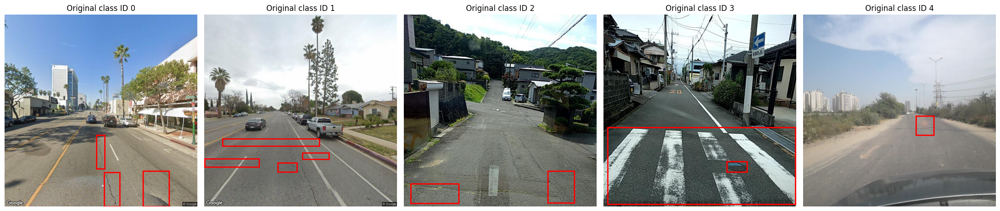

In [20]:
from pathlib import Path
from collections import defaultdict
import random

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

ROOT = Path(
    "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train"
)
IMAGE_DIR = ROOT / "images"
LABEL_DIR = ROOT / "labels"

random.seed(42)
examples = defaultdict(list)

# Find images containing each original source class.
for label_path in LABEL_DIR.glob("*.txt"):
    lines = label_path.read_text().splitlines()

    present_classes = set()
    for line in lines:
        parts = line.split()
        if len(parts) == 5:
            try:
                present_classes.add(int(parts[0]))
            except ValueError:
                pass

    for cls in present_classes:
        examples[cls].append(label_path)

# One example image per class ID.
fig, axes = plt.subplots(1, 5, figsize=(22, 6))

for cls in range(5):
    ax = axes[cls]
    ax.set_title(f"Original class ID {cls}")

    candidates = examples[cls]
    if not candidates:
        ax.text(0.5, 0.5, "No examples found", ha="center")
        ax.axis("off")
        continue

    label_path = random.choice(candidates)

    image_path = next(
        (
            p for p in IMAGE_DIR.glob(label_path.stem + ".*")
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        ),
        None
    )

    if image_path is None:
        ax.text(0.5, 0.5, "Image missing", ha="center")
        ax.axis("off")
        continue

    img = Image.open(image_path).convert("RGB")
    ax.imshow(img)
    width, height = img.size

    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue

        try:
            label_id = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:])
        except ValueError:
            continue

        # Draw only boxes belonging to this particular source class.
        if label_id != cls or bw <= 0 or bh <= 0:
            continue

        x = (xc - bw / 2) * width
        y = (yc - bh / 2) * height

        rect = patches.Rectangle(
            (x, y), bw * width, bh * height,
            linewidth=2, edgecolor="red", facecolor="none"
        )
        ax.add_patch(rect)

    ax.axis("off")
    print(f"Class {cls}: {image_path}")

plt.tight_layout()
plt.show()

Indexing image filenames...
Images indexed: 26869
Looking for 3 examples per class...
Class 0: found 3 examples
Class 1: found 3 examples
Class 2: found 3 examples
Class 4: found 3 examples


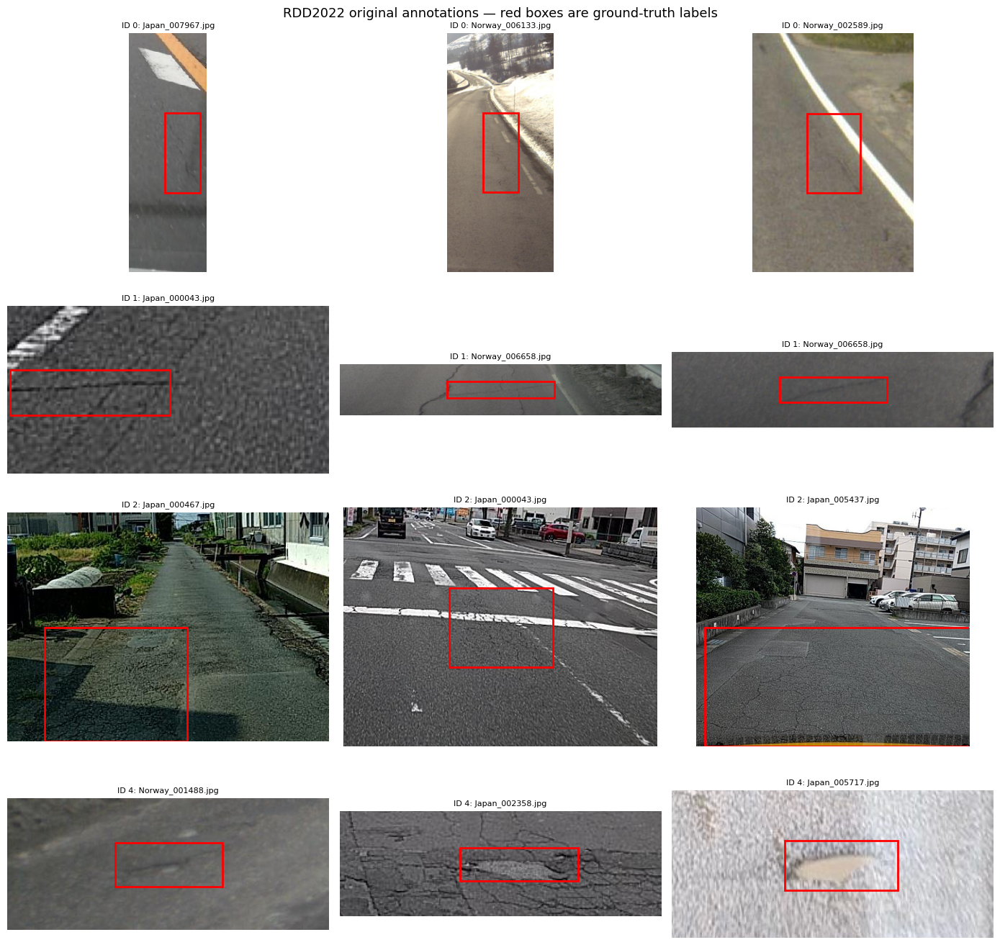

In [23]:
from pathlib import Path
from collections import defaultdict
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

ROOT = Path(
    "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train"
)
IMAGE_DIR = ROOT / "images"
LABEL_DIR = ROOT / "labels"

CLASS_NAMES = {
    0: "Source class 0",
    1: "Source class 1",
    2: "Source class 2",
    4: "Source class 4",
}
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Index images just once; avoids repeatedly searching 26,869 filenames.
print("Indexing image filenames...", flush=True)

image_index = {}
for p in IMAGE_DIR.iterdir():
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
        image_index.setdefault(p.stem, p)

print("Images indexed:", len(image_index), flush=True)

# Randomly inspect a small number of annotation files.
label_files = list(LABEL_DIR.glob("*.txt"))
random.Random(42).shuffle(label_files)

examples = defaultdict(list)
wanted = set(CLASS_NAMES)
print("Looking for 3 examples per class...", flush=True)

for label_path in label_files:
    image_path = image_index.get(label_path.stem)
    if image_path is None:
        continue

    try:
        lines = label_path.read_text().splitlines()
    except OSError:
        continue

    for line in lines:
        parts = line.split()
        if len(parts) != 5:
            continue

        try:
            cls = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:])
        except ValueError:
            continue

        if cls not in wanted or bw <= 0 or bh <= 0:
            continue

        if cls not in {c for c in wanted if len(examples[c]) >= 3}:
            examples[cls].append((image_path, xc, yc, bw, bh))

    if all(len(examples[c]) >= 3 for c in wanted):
        break

for cls in sorted(wanted):
    print(f"Class {cls}: found {len(examples[cls])} examples")

# Display zoomed crops of the actual labeled boxes.
fig, axes = plt.subplots(4, 3, figsize=(14, 14))
fig.suptitle(
    "RDD2022 original annotations — red boxes are ground-truth labels",
    fontsize=13
)

for row, cls in enumerate(sorted(wanted)):
    for col in range(3):
        ax = axes[row, col]
        ax.axis("off")

        if col >= len(examples[cls]):
            ax.set_title(f"{CLASS_NAMES[cls]} — no sample")
            continue

        image_path, xc, yc, bw, bh = examples[cls][col]

        with Image.open(image_path) as im:
            img = im.convert("RGB")

        W, H = img.size
        x1 = (xc - bw / 2) * W
        y1 = (yc - bh / 2) * H
        x2 = (xc + bw / 2) * W
        y2 = (yc + bh / 2) * H

        # Expand the crop to provide road context.
        mx = max(30, (x2 - x1))
        my = max(30, (y2 - y1))

        left = max(0, int(x1 - mx))
        top = max(0, int(y1 - my))
        right = min(W, int(x2 + mx))
        bottom = min(H, int(y2 + my))

        crop = img.crop((left, top, right, bottom))
        ax.imshow(crop)

        ax.add_patch(patches.Rectangle(
            (x1 - left, y1 - top),
            x2 - x1,
            y2 - y1,
            edgecolor="red",
            facecolor="none",
            linewidth=2
        ))

        ax.set_title(f"ID {cls}: {image_path.name}", fontsize=8)

plt.tight_layout()
plt.show()

In [24]:
from pathlib import Path
from collections import Counter
import yaml

ROOT = Path("/kaggle/working/roadguard_4class_v3")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Dataset exists:", ROOT.exists())

yaml_path = ROOT / "data.yaml"
assert yaml_path.is_file(), f"Missing dataset YAML: {yaml_path}"

config = yaml.safe_load(yaml_path.read_text())
print("\nClass names:", config["names"])
print("Number of classes:", config["nc"])

assert config["nc"] == 4
assert len(config["names"]) == 4

for split in ["train", "val", "test"]:
    image_dir = ROOT / "images" / split
    label_dir = ROOT / "labels" / split

    assert image_dir.is_dir(), f"Missing: {image_dir}"
    assert label_dir.is_dir(), f"Missing: {label_dir}"

    images = {
        p.stem for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    }
    labels = {p.stem for p in label_dir.glob("*.txt")}

    assert images == labels, (
        f"{split}: images and labels do not match. "
        f"Images without labels: {len(images-labels)}; "
        f"labels without images: {len(labels-images)}"
    )

    counts = Counter()
    empty = 0
    invalid = 0

    for label_path in label_dir.glob("*.txt"):
        text = label_path.read_text().strip()

        if not text:
            empty += 1
            continue

        for line in text.splitlines():
            parts = line.split()

            if len(parts) != 5:
                invalid += 1
                continue

            try:
                cls = int(parts[0])
                xc, yc, w, h = map(float, parts[1:])
            except ValueError:
                invalid += 1
                continue

            valid = (
                0 <= cls < 4
                and 0 <= xc <= 1
                and 0 <= yc <= 1
                and 0 < w <= 1
                and 0 < h <= 1
                and xc - w / 2 >= -1e-6
                and yc - h / 2 >= -1e-6
                and xc + w / 2 <= 1.000001
                and yc + h / 2 <= 1.000001
            )

            if not valid:
                invalid += 1
            else:
                counts[cls] += 1

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Matching label files:", len(labels))
    print("Objects by class:", dict(sorted(counts.items())))
    print("Empty label files:", empty)
    print("Invalid annotations:", invalid)

print("\nDataset structure verification finished.")

Dataset exists: True

Class names: ['D00_Longitudinal', 'D10_Transverse', 'D20_Alligator', 'D40_Pothole']
Number of classes: 4

TRAIN
Images: 26869
Matching label files: 26869
Objects by class: {0: 18201, 1: 8386, 2: 7526, 3: 4628}
Empty label files: 10138
Invalid annotations: 0

VAL
Images: 5758
Matching label files: 5758
Objects by class: {0: 3890, 1: 1769, 2: 1553, 3: 965}
Empty label files: 2265
Invalid annotations: 0

TEST
Images: 5758
Matching label files: 5758
Objects by class: {0: 3925, 1: 1675, 2: 1537, 3: 951}
Empty label files: 2215
Invalid annotations: 0

Dataset structure verification finished.


In [26]:
from pathlib import Path
import shutil

print("=== AVAILABLE DISK SPACE ===")
usage = shutil.disk_usage("/kaggle/working")
print("Total GB:", round(usage.total / 1024**3, 2))
print("Used GB:", round(usage.used / 1024**3, 2))
print("Free GB:", round(usage.free / 1024**3, 2))

print("\n=== DATASET IMAGE FOLDER LINKS ===")
for p in [
    Path("/kaggle/working/roadguard_4class_v3/images/train"),
    Path("/kaggle/working/roadguard_4class_v3/images/val"),
    Path("/kaggle/working/roadguard_4class_v3/images/test"),
]:
    print(p, "| Symlink:", p.is_symlink(), "| Exists:", p.exists())

print("\n=== CURRENT RUN FILES ===")
run = Path("/kaggle/working/RoadGuard_Run/yolo11m_rdd2022_4class_v1")
if run.exists():
    for p in run.rglob("*"):
        if p.is_file() and (
            p.suffix in {".pt", ".csv", ".yaml"}
        ):
            print(p, "|", round(p.stat().st_size / 1024**2, 2), "MB")

=== AVAILABLE DISK SPACE ===
Total GB: 19.52
Used GB: 0.19
Free GB: 19.32

=== DATASET IMAGE FOLDER LINKS ===
/kaggle/working/roadguard_4class_v3/images/train | Symlink: True | Exists: True
/kaggle/working/roadguard_4class_v3/images/val | Symlink: True | Exists: True
/kaggle/working/roadguard_4class_v3/images/test | Symlink: True | Exists: True

=== CURRENT RUN FILES ===
/kaggle/working/RoadGuard_Run/yolo11m_rdd2022_4class_v1/args.yaml | 0.0 MB


In [27]:
from pathlib import Path
import shutil

SOURCE = Path(
    "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT"
)
DEST = Path("/kaggle/working/roadguard_4class_v3")

free_gb = shutil.disk_usage("/kaggle/working").free / (1024**3)

print("Free disk space:", round(free_gb, 2), "GB")

for split in ["train", "val", "test"]:
    image_dir = SOURCE / split / "images"

    total_bytes = 0
    image_count = 0

    for p in image_dir.iterdir():
        if p.is_file():
            total_bytes += p.stat().st_size
            image_count += 1

    print(
        f"{split}: {image_count} images, "
        f"{total_bytes / (1024**3):.2f} GB"
    )

print("\nConverted dataset labels:")
for split in ["train", "val", "test"]:
    label_dir = DEST / "labels" / split
    if label_dir.is_dir():
        print(split, "labels:", sum(1 for _ in label_dir.glob("*.txt")))
    else:
        print(split, "labels directory missing")

Free disk space: 19.32 GB
train: 26869 images, 7.22 GB
val: 5758 images, 1.57 GB
test: 5758 images, 1.52 GB

Converted dataset labels:
train labels: 26869
val labels: 5758
test labels: 5758


In [28]:

from pathlib import Path
from collections import Counter
import shutil
import os
import yaml

SOURCE = Path(
    "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT"
)
CONVERTED = Path("/kaggle/working/roadguard_4class_v3")
DEST = Path("/kaggle/working/roadguard_4class_physical")

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
NAMES = [
    "D00_Longitudinal",
    "D10_Transverse",
    "D20_Alligator",
    "D40_Pothole",
]

assert SOURCE.is_dir(), f"Original dataset missing: {SOURCE}"
assert (CONVERTED / "data.yaml").is_file(), "Converted YAML missing."

# Estimate required space before copying.
all_source_images = []
for split in ["train", "val", "test"]:
    image_dir = SOURCE / split / "images"
    assert image_dir.is_dir(), f"Missing: {image_dir}"

    all_source_images.extend(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )

required_bytes = sum(p.stat().st_size for p in all_source_images)
free_bytes = shutil.disk_usage("/kaggle/working").free
reserve_bytes = 5 * 1024**3

print("Images to copy:", len(all_source_images))
print("Estimated image storage:", round(required_bytes / 1024**3, 2), "GiB")
print("Free storage:", round(free_bytes / 1024**3, 2), "GiB")

if free_bytes < required_bytes + reserve_bytes:
    raise RuntimeError(
        "Insufficient free space for the image copy plus a 5 GiB reserve. "
        "Nothing was copied by this cell."
    )

DEST.mkdir(parents=True, exist_ok=True)

def copy_atomically(src, dst):
    """Copy a file safely; reuse an existing complete copy."""
    if dst.is_symlink():
        raise RuntimeError(f"Unexpected symlink at destination: {dst}")

    if dst.is_file() and dst.stat().st_size == src.stat().st_size:
        return False

    tmp = dst.with_name(dst.name + ".partial")
    shutil.copy2(src, tmp)

    if tmp.stat().st_size != src.stat().st_size:
        tmp.unlink(missing_ok=True)
        raise IOError(f"Copy size mismatch: {src}")

    os.replace(tmp, dst)
    return True

for split in ["train", "val", "test"]:
    print(f"\n=== COPYING {split.upper()} ===", flush=True)

    src_images = SOURCE / split / "images"
    src_labels = CONVERTED / "labels" / split

    dst_images = DEST / "images" / split
    dst_labels = DEST / "labels" / split

    assert src_labels.is_dir(), f"Converted labels missing: {src_labels}"

    image_files = {
        p.stem: p for p in src_images.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    }
    label_files = {p.stem: p for p in src_labels.glob("*.txt")}

    if set(image_files) != set(label_files):
        raise ValueError(
            f"{split}: image/label mismatch. "
            f"Images without labels: {len(set(image_files)-set(label_files))}; "
            f"labels without images: {len(set(label_files)-set(image_files))}"
        )

    # Refuse to write through an unexpected symbolic link.
    if dst_images.is_symlink() or dst_labels.is_symlink():
        raise RuntimeError(
            f"Destination image/label directory is a symlink for {split}."
        )

    dst_images.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    copied = 0
    reused = 0

    for i, (stem, src) in enumerate(sorted(image_files.items()), start=1):
        changed = copy_atomically(src, dst_images / src.name)
        copied += int(changed)
        reused += int(not changed)

        if i % 1000 == 0 or i == len(image_files):
            print(
                f"{split}: {i}/{len(image_files)} images; "
                f"copied this run={copied}, already present={reused}",
                flush=True
            )

    # Copy the already-converted four-class labels.
    for i, (stem, src) in enumerate(sorted(label_files.items()), start=1):
        copy_atomically(src, dst_labels / src.name)

        if i % 5000 == 0 or i == len(label_files):
            print(f"{split}: labels {i}/{len(label_files)}", flush=True)

    # Confirm images are real files, not symbolic links.
    assert len(list(dst_images.iterdir())) == len(image_files)
    assert not dst_images.is_symlink()
    assert not dst_labels.is_symlink()

# Write a YAML pointing to the physical destination.
data_config = {
    "path": str(DEST),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 4,
    "names": NAMES,
}

yaml_path = DEST / "data.yaml"
yaml_path.write_text(yaml.safe_dump(data_config, sort_keys=False))

print("\n=== PHYSICAL DATASET CREATED ===")
print("Dataset:", DEST)
print("YAML:", yaml_path)
print(yaml_path.read_text())
print("Remaining free GiB:", round(
    shutil.disk_usage("/kaggle/working").free / 1024**3, 2
))


Images to copy: 38385
Estimated image storage: 10.31 GiB
Free storage: 19.32 GiB

=== COPYING TRAIN ===
train: 1000/26869 images; copied this run=1000, already present=0
train: 2000/26869 images; copied this run=2000, already present=0
train: 3000/26869 images; copied this run=3000, already present=0
train: 4000/26869 images; copied this run=4000, already present=0
train: 5000/26869 images; copied this run=5000, already present=0
train: 6000/26869 images; copied this run=6000, already present=0
train: 7000/26869 images; copied this run=7000, already present=0
train: 8000/26869 images; copied this run=8000, already present=0
train: 9000/26869 images; copied this run=9000, already present=0
train: 10000/26869 images; copied this run=10000, already present=0
train: 11000/26869 images; copied this run=11000, already present=0
train: 12000/26869 images; copied this run=12000, already present=0
train: 13000/26869 images; copied this run=13000, already present=0
train: 14000/26869 images; cop

In [29]:
from pathlib import Path
from collections import Counter
import yaml
import shutil

ROOT = Path("/kaggle/working/roadguard_4class_physical")
DATA_YAML = ROOT / "data.yaml"
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

assert DATA_YAML.is_file(), "Dataset YAML is missing."

config = yaml.safe_load(DATA_YAML.read_text())
assert config["nc"] == 4
assert len(config["names"]) == 4

print("Dataset:", ROOT)
print("Class names:", config["names"])

for split in ["train", "val", "test"]:
    image_dir = ROOT / "images" / split
    label_dir = ROOT / "labels" / split

    assert image_dir.is_dir() and not image_dir.is_symlink()
    assert label_dir.is_dir() and not label_dir.is_symlink()

    images = {
        p.stem for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in EXTS
    }
    labels = {p.stem for p in label_dir.glob("*.txt")}

    assert images == labels, f"{split}: image/label mismatch"

    counts = Counter()
    errors = []

    for label_path in label_dir.glob("*.txt"):
        for line_no, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            parts = line.split()

            try:
                assert len(parts) == 5
                cls = int(parts[0])
                xc, yc, w, h = map(float, parts[1:])

                assert cls in range(4), f"Unexpected class ID {cls}"
                assert 0 <= xc <= 1 and 0 <= yc <= 1
                assert 0 < w <= 1 and 0 < h <= 1
                assert xc - w / 2 >= -1e-6
                assert yc - h / 2 >= -1e-6
                assert xc + w / 2 <= 1.000001
                assert yc + h / 2 <= 1.000001

                counts[cls] += 1

            except (AssertionError, ValueError) as exc:
                errors.append(f"{label_path.name}:{line_no}: {exc}")

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Object counts:", dict(sorted(counts.items())))
    print("Invalid annotations:", len(errors))

    if errors:
        print("Examples:", errors[:5])
        raise RuntimeError(f"{split} failed verification")

print("\nFree disk space:",
      round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2),
      "GiB")
print("\nDataset checks passed.")

Dataset: /kaggle/working/roadguard_4class_physical
Class names: ['D00_Longitudinal', 'D10_Transverse', 'D20_Alligator', 'D40_Pothole']

TRAIN
Images: 26869
Label files: 26869
Object counts: {0: 18201, 1: 8386, 2: 7526, 3: 4628}
Invalid annotations: 0

VAL
Images: 5758
Label files: 5758
Object counts: {0: 3890, 1: 1769, 2: 1553, 3: 965}
Invalid annotations: 0

TEST
Images: 5758
Label files: 5758
Object counts: {0: 3925, 1: 1675, 2: 1537, 3: 951}
Invalid annotations: 0

Free disk space: 8.84 GiB

Dataset checks passed.


In [31]:

from pathlib import Path
import shutil
import torch
import yaml
from ultralytics import YOLO

DATA_YAML = "/kaggle/working/roadguard_4class_physical/data.yaml"
PROJECT = "/kaggle/working/RoadGuard_Fast"
RUN_NAME = "yolo11s_512_v1"
RUN_DIR = Path(PROJECT) / RUN_NAME

assert Path(DATA_YAML).is_file(), "Dataset YAML not found."
assert torch.cuda.is_available(), "GPU is not available."

cfg = yaml.safe_load(Path(DATA_YAML).read_text())
assert cfg["nc"] == 4
assert cfg["names"] == [
    "D00_Longitudinal",
    "D10_Transverse",
    "D20_Alligator",
    "D40_Pothole",
]

if RUN_DIR.exists():
    raise RuntimeError(
        f"Run already exists: {RUN_DIR}. "
        "Inspect its checkpoints before proceeding."
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Free disk (GiB):",
      round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2))

# Smaller model for faster training.
model = YOLO("yolo11s.pt")

results = model.train(
    data=DATA_YAML,
    epochs=15,
    imgsz=512,
    batch=32,
    workers=2,
    device=0,
    patience=5,
    optimizer="AdamW",
    lr0=0.001,
    cos_lr=True,
    seed=42,
    amp=True,
    cache=False,
    project=PROJECT,
    name=RUN_NAME,
    save=True,
    save_period=1,
    plots=True,
    verbose=True,
)

weights = RUN_DIR / "weights"
print("\nTraining finished or stopped.")
print("Weights directory:", weights)

for p in sorted(weights.glob("*.pt")):
    print(p.name, round(p.stat().st_size / 1024**2, 2), "MB")

print("Results CSV exists:", (RUN_DIR / "results.csv").is_file())


GPU: Tesla T4
Free disk (GiB): 8.83
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/roadguard_4class_physical/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=y

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/15      5.25G      2.183      2.601       1.79         38        512: 100% ━━━━━━━━━━━━ 840/840 3.2it/s 4:250.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 90/90 2.0it/s 44.2s0.4ss
                   all       5758       8177      0.308      0.226      0.174     0.0694

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/15      5.25G      2.107      2.511      1.742         53        512: 100% ━━━━━━━━━━━━ 840/840 3.2it/s 4:240.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 90/90 2.0it/s 44.9s0.4ss
                   all       5758       8177      0.307      0.274      0.197     0.0747

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/15      5.25G      2.055      2.419      1.695         66        512: 100% ━━━━━━━━━━━━ 840/840 3.2it/s 4:250.2ss
                 Class     Im

In [32]:

from pathlib import Path
import shutil
import os

RUN = Path(
    "/kaggle/working/RoadGuard_Fast/yolo11s_512_v1"
)
WEIGHTS = RUN / "weights"

BACKUP = Path(
    "/kaggle/working/RoadGuard_Persistent_Backup"
)
BACKUP_WEIGHTS = BACKUP / "weights"
BACKUP_WEIGHTS.mkdir(parents=True, exist_ok=True)

assert WEIGHTS.is_dir(), f"Checkpoint directory not found: {WEIGHTS}"

# Copy every saved checkpoint without deleting the original.
checkpoints = sorted(WEIGHTS.glob("*.pt"))
assert checkpoints, "No checkpoint files found."

for source in checkpoints:
    destination = BACKUP_WEIGHTS / source.name
    temporary = BACKUP_WEIGHTS / (source.name + ".tmp")

    shutil.copy2(source, temporary)

    if temporary.stat().st_size != source.stat().st_size:
        temporary.unlink(missing_ok=True)
        raise IOError(f"Size verification failed: {source.name}")

    os.replace(temporary, destination)
    print(
        "Verified:",
        destination.name,
        f"| {destination.stat().st_size / 1024**2:.2f} MB"
    )

# Preserve key experiment results and model configuration.
for name in [
    "results.csv",
    "args.yaml",
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
]:
    source = RUN / name

    if source.is_file():
        destination = BACKUP / name
        shutil.copy2(source, destination)
        print("Saved result:", name)

print("\nOriginal checkpoint count:", len(checkpoints))
print("Backup folder:", BACKUP)
print("Free disk space (GiB):",
      round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2))


Verified: best.pt | 18.27 MB
Verified: epoch0.pt | 72.46 MB
Verified: epoch1.pt | 72.47 MB
Verified: epoch10.pt | 72.47 MB
Verified: epoch11.pt | 72.47 MB
Verified: epoch12.pt | 72.47 MB
Verified: epoch13.pt | 72.47 MB
Verified: epoch14.pt | 72.47 MB
Verified: epoch2.pt | 72.47 MB
Verified: epoch3.pt | 72.47 MB
Verified: epoch4.pt | 72.47 MB
Verified: epoch5.pt | 72.47 MB
Verified: epoch6.pt | 72.47 MB
Verified: epoch7.pt | 72.47 MB
Verified: epoch8.pt | 72.47 MB
Verified: epoch9.pt | 72.47 MB
Verified: last.pt | 18.27 MB
Saved result: results.csv
Saved result: args.yaml
Saved result: results.png
Saved result: confusion_matrix.png
Saved result: confusion_matrix_normalized.png

Original checkpoint count: 17
Backup folder: /kaggle/working/RoadGuard_Persistent_Backup
Free disk space (GiB): 6.61


In [33]:

from pathlib import Path
import shutil
import yaml

run = Path("/kaggle/working/RoadGuard_Fast/yolo11s_512_v1")
backup = Path("/kaggle/working/RoadGuard_Persistent_Backup")
source_weights = run / "weights"
backup_weights = backup / "weights"

assert source_weights.is_dir(), "Original checkpoint folder is missing."
assert backup_weights.is_dir(), "Backup checkpoint folder is missing."

source_files = {p.name: p for p in source_weights.glob("*.pt")}
backup_files = {p.name: p for p in backup_weights.glob("*.pt")}

missing = sorted(set(source_files) - set(backup_files))
mismatched = [
    name for name in source_files.keys() & backup_files.keys()
    if source_files[name].stat().st_size != backup_files[name].stat().st_size
]

print("Original checkpoints:", len(source_files))
print("Backup checkpoints:", len(backup_files))
print("Missing from backup:", missing)
print("Size mismatches:", mismatched)

assert not missing, "Some checkpoint files are missing from the backup."
assert not mismatched, "Some checkpoint copies have different sizes."
assert "best.pt" in backup_files and "last.pt" in backup_files

# Preserve other evaluation artifacts when available.
for name in [
    "results.csv", "args.yaml", "results.png",
    "confusion_matrix.png", "confusion_matrix_normalized.png",
    "PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"
]:
    src = run / name
    dst = backup / name

    if src.is_file() and not dst.exists():
        shutil.copy2(src, dst)

manifest = [
    "RoadGuard AI - YOLO11s 512px training",
    "Dataset: RDD2022-derived four-class dataset",
    "Training epochs completed: 15",
    "Validation precision: 0.551",
    "Validation recall: 0.461",
    "Validation mAP50: 0.477",
    "Validation mAP50-95: 0.233",
    "",
    "Checkpoint files:"
]

for name, p in sorted(backup_files.items()):
    manifest.append(
        f"{name} | {p.stat().st_size / (1024**2):.2f} MB"
    )

(backup / "checkpoint_manifest.txt").write_text("\n".join(manifest))

print("\nBackup verified:", backup)
print("Manifest:", backup / "checkpoint_manifest.txt")
print("Free disk (GiB):",
      round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2))


Original checkpoints: 17
Backup checkpoints: 17
Missing from backup: []
Size mismatches: []

Backup verified: /kaggle/working/RoadGuard_Persistent_Backup
Manifest: /kaggle/working/RoadGuard_Persistent_Backup/checkpoint_manifest.txt
Free disk (GiB): 6.61


Loaded: /kaggle/working/RoadGuard_Fast/yolo11s_512_v1/weights/best.pt
Classes: {0: 'D00_Longitudinal', 1: 'D10_Transverse', 2: 'D20_Alligator', 3: 'D40_Pothole'}


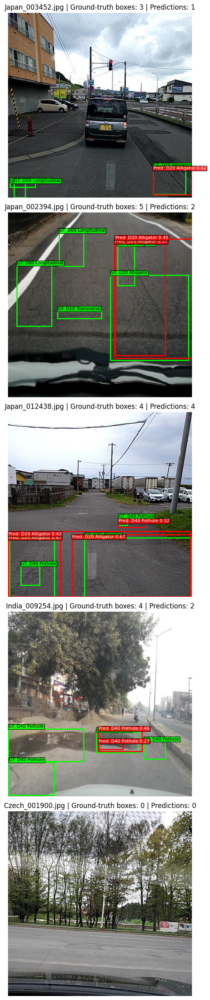

In [34]:
from pathlib import Path
from collections import defaultdict
import random

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO

ROOT = Path("/kaggle/working/roadguard_4class_physical")
IMAGE_DIR = ROOT / "images" / "val"
LABEL_DIR = ROOT / "labels" / "val"

checkpoint_candidates = [
    Path("/kaggle/working/RoadGuard_Fast/yolo11s_512_v1/weights/best.pt"),
    Path("/kaggle/working/RoadGuard_Persistent_Backup/weights/best.pt"),
    Path("/kaggle/working/RoadGuard_Persistent_Backup/best.pt"),
]

CHECKPOINT = next(
    (p for p in checkpoint_candidates if p.is_file()),
    None
)

if CHECKPOINT is None:
    raise FileNotFoundError(
        "best.pt was not found in the expected locations. "
        "Locate the saved checkpoint before running inference."
    )

assert IMAGE_DIR.is_dir(), f"Validation images missing: {IMAGE_DIR}"
assert LABEL_DIR.is_dir(), f"Validation labels missing: {LABEL_DIR}"

model = YOLO(str(CHECKPOINT))
print("Loaded:", CHECKPOINT)
print("Classes:", model.names)

CLASS_NAMES = {
    0: "D00 Longitudinal",
    1: "D10 Transverse",
    2: "D20 Alligator",
    3: "D40 Pothole",
}

# Select real examples without scanning image pixels.
examples = defaultdict(list)
empty_examples = []

for label_path in LABEL_DIR.glob("*.txt"):
    image_path = IMAGE_DIR / f"{label_path.stem}.jpg"
    if not image_path.is_file():
        # Support other image extensions.
        matches = [
            p for p in IMAGE_DIR.glob(label_path.stem + ".*")
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
        ]
        if not matches:
            continue
        image_path = matches[0]

    text = label_path.read_text().strip()

    if not text:
        empty_examples.append(image_path)
        continue

    present = set()
    for line in text.splitlines():
        parts = line.split()
        if len(parts) == 5:
            try:
                present.add(int(parts[0]))
            except ValueError:
                pass

    for cls in present:
        if cls in CLASS_NAMES:
            examples[cls].append(image_path)

rng = random.Random(42)
selected = []

for cls in range(4):
    choices = examples[cls]
    if choices:
        selected.append((rng.choice(choices), cls))

if empty_examples:
    selected.append((rng.choice(empty_examples), None))

if not selected:
    raise RuntimeError("No suitable validation examples were found.")

fig, axes = plt.subplots(
    len(selected), 1, figsize=(14, 5 * len(selected))
)
if len(selected) == 1:
    axes = [axes]

for ax, (image_path, target_class) in zip(axes, selected):
    with Image.open(image_path) as source_image:
        image = source_image.convert("RGB")

    width, height = image.size
    ax.imshow(image)

    label_path = LABEL_DIR / f"{image_path.stem}.txt"
    gt_count = 0

    # Ground truth boxes: green.
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue

        cls = int(parts[0])
        xc, yc, bw, bh = map(float, parts[1:])

        x = (xc - bw / 2) * width
        y = (yc - bh / 2) * height

        rect = patches.Rectangle(
            (x, y), bw * width, bh * height,
            linewidth=2, edgecolor="lime", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x, max(0, y - 4),
            f"GT: {CLASS_NAMES.get(cls, str(cls))}",
            color="black", fontsize=8,
            bbox=dict(facecolor="lime", alpha=0.8, pad=1)
        )
        gt_count += 1

    # Actual model predictions: red.
    prediction = model.predict(
        source=str(image_path),
        imgsz=512,
        conf=0.25,
        iou=0.7,
        device=0,
        verbose=False
    )[0]

    pred_count = 0
    for box in prediction.boxes:
        cls = int(box.cls.item())
        confidence = float(box.conf.item())
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="red", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, min(height - 5, y1 + 12),
            f"Pred: {CLASS_NAMES.get(cls, str(cls))} {confidence:.2f}",
            color="white", fontsize=8,
            bbox=dict(facecolor="red", alpha=0.8, pad=1)
        )
        pred_count += 1

    ax.set_title(
        f"{image_path.name} | Ground-truth boxes: {gt_count} "
        f"| Predictions: {pred_count}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [35]:

from pathlib import Path
import csv
from ultralytics import YOLO

CHECKPOINT = Path(
    "/kaggle/working/RoadGuard_Fast/yolo11s_512_v1/weights/best.pt"
)
DATA_YAML = Path(
    "/kaggle/working/roadguard_4class_physical/data.yaml"
)
OUT = Path("/kaggle/working/RoadGuard_Threshold_Check")
OUT.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT.is_file(), f"Checkpoint missing: {CHECKPOINT}"
assert DATA_YAML.is_file(), f"Dataset YAML missing: {DATA_YAML}"

model = YOLO(str(CHECKPOINT))
thresholds = [0.10, 0.25, 0.35, 0.50]
rows = []

for conf in thresholds:
    print(f"\nEvaluating confidence threshold {conf}...", flush=True)

    result = model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=512,
        batch=16,
        workers=2,
        device=0,
        conf=conf,
        iou=0.7,
        plots=False,
        project=str(OUT),
        name=f"conf_{int(conf * 100):02d}",
        exist_ok=True,
        verbose=False,
    )

    row = {
        "confidence_threshold": conf,
        "precision": float(result.box.mp),
        "recall": float(result.box.mr),
        "mAP50": float(result.box.map50),
        "mAP50_95": float(result.box.map),
    }
    rows.append(row)
    print(row)

csv_path = OUT / "threshold_metrics.csv"

with csv_path.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

print("\n=== MEASURED VALIDATION RESULTS ===")
for row in rows:
    print(row)

print("\nSaved results to:", csv_path)



Evaluating confidence threshold 0.1...
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2177.1±1553.3 MB/s, size: 527.1 KB)
val: Scanning /kaggle/working/roadguard_4class_physical/labels/val.cache... 5758 images, 2265 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 1.6Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 360/360 5.5it/s 1:050.2sss
                   all       5758       8177      0.551      0.463      0.436      0.213
Speed: 0.5ms preprocess, 5.7ms inference, 0.0ms loss, 0.6ms postprocess per image
{'confidence_threshold': 0.1, 'precision': 0.5508006286368058, 'recall': 0.46288693878529125, 'mAP50': 0.43610653702655644, 'mAP50_95': 0.212963187900844}

Evaluating confidence threshold 0.25...
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2

In [36]:

from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from ultralytics import YOLO

ROOT = Path("/kaggle/working/roadguard_4class_physical")
IMAGE_DIR = ROOT / "images" / "val"
LABEL_DIR = ROOT / "labels" / "val"

CHECKPOINT = Path(
    "/kaggle/working/RoadGuard_Fast/yolo11s_512_v1/weights/best.pt"
)

assert CHECKPOINT.is_file(), f"Checkpoint not found: {CHECKPOINT}"
assert IMAGE_DIR.is_dir() and LABEL_DIR.is_dir()

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
THRESHOLDS = [0.10, 0.25, 0.35, 0.50]
IOU_THRESHOLD = 0.50

CLASS_NAMES = {
    0: "D00_Longitudinal",
    1: "D10_Transverse",
    2: "D20_Alligator",
    3: "D40_Pothole",
}

images = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

print("Validation images:", len(images))
print("Checkpoint:", CHECKPOINT)

model = YOLO(str(CHECKPOINT))

# Collect predictions once. The minimum inference confidence is below
# every threshold that will be evaluated.
predictions = {}
image_shapes = {}

for result in tqdm(
    model.predict(
        source=str(IMAGE_DIR),
        imgsz=512,
        batch=16,
        conf=0.05,
        iou=0.7,
        max_det=300,
        device=0,
        stream=True,
        verbose=False,
    ),
    total=len(images),
    desc="Running validation inference"
):
    stem = Path(result.path).stem
    image_shapes[stem] = result.orig_shape

    records = []
    if result.boxes is not None and len(result.boxes):
        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)

        for box, score, cls in zip(boxes, scores, classes):
            records.append((int(cls), float(score), box.astype(float)))

    predictions[stem] = records

# Load ground-truth boxes from the verified validation labels.
ground_truth = {}

for image in images:
    label_path = LABEL_DIR / f"{image.stem}.txt"
    if not label_path.is_file():
        raise FileNotFoundError(f"Missing label: {label_path}")

    h, w = image_shapes[image.stem]
    boxes = []

    text = label_path.read_text().strip()
    if text:
        for line in text.splitlines():
            parts = line.split()
            if len(parts) != 5:
                raise ValueError(f"Malformed label: {label_path}")

            cls = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:])

            if cls not in CLASS_NAMES:
                raise ValueError(f"Unexpected class ID {cls}: {label_path}")

            xyxy = np.array([
                (xc - bw / 2) * w,
                (yc - bh / 2) * h,
                (xc + bw / 2) * w,
                (yc + bh / 2) * h,
            ], dtype=float)

            boxes.append((cls, xyxy))

    ground_truth[image.stem] = boxes

if set(ground_truth) != set(predictions):
    missing = set(ground_truth) - set(predictions)
    extra = set(predictions) - set(ground_truth)
    raise RuntimeError(
        f"Inference/label mismatch. Missing predictions: {len(missing)}; "
        f"unexpected predictions: {len(extra)}"
    )

def box_iou(one, many):
    """IoU between one xyxy box and an array of xyxy boxes."""
    if len(many) == 0:
        return np.zeros(0, dtype=float)

    x1 = np.maximum(one[0], many[:, 0])
    y1 = np.maximum(one[1], many[:, 1])
    x2 = np.minimum(one[2], many[:, 2])
    y2 = np.minimum(one[3], many[:, 3])

    intersection = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)

    area_one = max(0, one[2] - one[0]) * max(0, one[3] - one[1])
    areas_many = (
        np.maximum(0, many[:, 2] - many[:, 0])
        * np.maximum(0, many[:, 3] - many[:, 1])
    )
    union = area_one + areas_many - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0
    )

rows = []

# Confidence filtering plus one-to-one, class-aware matching:
# a prediction is TP only if its class matches and IoU >= 0.50.
for threshold in THRESHOLDS:
    per_class = {}

    for cls, class_name in CLASS_NAMES.items():
        tp = fp = fn = 0

        for stem in ground_truth:
            gt_boxes = [
                box for gt_cls, box in ground_truth[stem]
                if gt_cls == cls
            ]
            pred_boxes = [
                (score, box)
                for pred_cls, score, box in predictions[stem]
                if pred_cls == cls and score >= threshold
            ]

            pred_boxes.sort(key=lambda item: item[0], reverse=True)

            gt_array = (
                np.stack(gt_boxes) if gt_boxes
                else np.zeros((0, 4), dtype=float)
            )
            matched_gt = set()

            for score, pred_box in pred_boxes:
                ious = box_iou(pred_box, gt_array)

                # A ground-truth object can match at most one prediction.
                for index in matched_gt:
                    ious[index] = -1.0

                if len(ious) and float(ious.max()) >= IOU_THRESHOLD:
                    matched_gt.add(int(ious.argmax()))
                    tp += 1
                else:
                    fp += 1

            fn += len(gt_boxes) - len(matched_gt)

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0

        per_class[cls] = (tp, fp, fn, precision, recall)

        rows.append({
            "threshold": threshold,
            "class_id": cls,
            "class_name": class_name,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "precision": precision,
            "recall": recall,
        })

    total_tp = sum(v[0] for v in per_class.values())
    total_fp = sum(v[1] for v in per_class.values())
    total_fn = sum(v[2] for v in per_class.values())

    micro_precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0
    micro_recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0

    print(f"\n=== CONFIDENCE {threshold:.2f} ===")
    print(
        f"Overall TP={total_tp}, FP={total_fp}, FN={total_fn}, "
        f"precision={micro_precision:.4f}, recall={micro_recall:.4f}"
    )

    for cls, name in CLASS_NAMES.items():
        tp, fp, fn, precision, recall = per_class[cls]
        print(
            f"{name}: TP={tp}, FP={fp}, FN={fn}, "
            f"P={precision:.4f}, R={recall:.4f}"
        )

output_path = Path("/kaggle/working/RoadGuard_Threshold_Check")
output_path.mkdir(parents=True, exist_ok=True)

csv_path = output_path / "direct_threshold_metrics.csv"
pd.DataFrame(rows).to_csv(csv_path, index=False)

print("\nSaved actual threshold-specific metrics to:", csv_path)
print("Matching protocol: same class, IoU >= 0.50, one-to-one matching.")


Validation images: 5758
Checkpoint: /kaggle/working/RoadGuard_Fast/yolo11s_512_v1/weights/best.pt


Running validation inference:   0%|          | 0/5758 [00:00<?, ?it/s]


=== CONFIDENCE 0.10 ===
Overall TP=4911, FP=9911, FN=3266, precision=0.3313, recall=0.6006
D00_Longitudinal: TP=2321, FP=5037, FN=1569, P=0.3154, R=0.5967
D10_Transverse: TP=1071, FP=2094, FN=698, P=0.3384, R=0.6054
D20_Alligator: TP=1046, FP=1727, FN=507, P=0.3772, R=0.6735
D40_Pothole: TP=473, FP=1053, FN=492, P=0.3100, R=0.4902

=== CONFIDENCE 0.25 ===
Overall TP=3539, FP=2380, FN=4638, precision=0.5979, recall=0.4328
D00_Longitudinal: TP=1693, FP=1183, FN=2197, P=0.5887, R=0.4352
D10_Transverse: TP=712, FP=517, FN=1057, P=0.5793, R=0.4025
D20_Alligator: TP=819, FP=438, FN=734, P=0.6516, R=0.5274
D40_Pothole: TP=315, FP=242, FN=650, P=0.5655, R=0.3264

=== CONFIDENCE 0.35 ===
Overall TP=2715, FP=1063, FN=5462, precision=0.7186, recall=0.3320
D00_Longitudinal: TP=1317, FP=533, FN=2573, P=0.7119, R=0.3386
D10_Transverse: TP=506, FP=204, FN=1263, P=0.7127, R=0.2860
D20_Alligator: TP=672, FP=220, FN=881, P=0.7534, R=0.4327
D40_Pothole: TP=220, FP=106, FN=745, P=0.6748, R=0.2280

=== CO

In [37]:

from pathlib import Path
import shutil
import os
import torch
from ultralytics import YOLO

BEST = Path(
    "/kaggle/working/RoadGuard_Fast/yolo11s_512_v1/weights/best.pt"
)
DATA = Path("/kaggle/working/roadguard_4class_physical/data.yaml")

PROJECT = Path("/kaggle/working/RoadGuard_Finetune")
RUN_NAME = "yolo11s_512_ft5"
RUN_DIR = PROJECT / RUN_NAME

BACKUP = Path("/kaggle/working/RoadGuard_Finetune_Backup")
BACKUP.mkdir(parents=True, exist_ok=True)

assert BEST.is_file(), f"Existing trained model not found: {BEST}"
assert DATA.is_file(), f"Dataset YAML missing: {DATA}"
assert torch.cuda.is_available(), "CUDA GPU unavailable."

free_gb = shutil.disk_usage("/kaggle/working").free / 1024**3
print("GPU:", torch.cuda.get_device_name(0))
print("Free disk space:", round(free_gb, 2), "GiB")

if free_gb < 2:
    raise RuntimeError("Insufficient free disk space for another experiment.")

if RUN_DIR.exists():
    raise RuntimeError(
        f"Run already exists: {RUN_DIR}. "
        "Inspect its checkpoints before proceeding."
    )

model = YOLO(str(BEST))

# Back up latest and best weights after each model-save event.
def backup_weights(trainer):
    weights_dir = Path(trainer.save_dir) / "weights"

    for name in ["last.pt", "best.pt"]:
        src = weights_dir / name

        if src.is_file():
            tmp = BACKUP / f"{name}.tmp"
            dst = BACKUP / name
            shutil.copy2(src, tmp)

            if tmp.stat().st_size != src.stat().st_size:
                tmp.unlink(missing_ok=True)
                raise IOError(f"Checkpoint verification failed: {name}")

            os.replace(tmp, dst)

model.add_callback("on_model_save", backup_weights)

results = model.train(
    data=str(DATA),
    epochs=5,
    imgsz=512,
    batch=32,
    workers=2,
    device=0,
    optimizer="AdamW",
    lr0=0.0003,
    cos_lr=True,
    patience=5,
    close_mosaic=2,
    seed=42,
    amp=True,
    cache=False,
    project=str(PROJECT),
    name=RUN_NAME,
    save=True,
    save_period=1,
    plots=True,
    verbose=True,
)

print("\n=== FINE-TUNING FINISHED ===")
weights_dir = RUN_DIR / "weights"

for p in sorted(weights_dir.glob("*.pt")):
    print(p.name, round(p.stat().st_size / 1024**2, 2), "MB")

print("\nRecovery directory:", BACKUP)
print("Training results:", RUN_DIR / "results.csv")
print("Free disk remaining:",
      round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2), "GiB")


GPU: Tesla T4
Free disk space: 6.61 GiB
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/roadguard_4class_physical/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/RoadGuard_Fast/yolo11s_512_v1/weights/best.p

In [39]:

from pathlib import Path
import shutil
import os
import json
import hashlib

RUN = Path("/kaggle/working/RoadGuard_Finetune/yolo11s_512_ft5")
BASE = Path("/kaggle/working/RoadGuard_Fast/yolo11s_512_v1")
PACKAGE = Path("/kaggle/working/RoadGuard_Finetuned_Release_v1")

WEIGHTS = RUN / "weights"
BASE_BEST = BASE / "weights" / "best.pt"

assert (WEIGHTS / "best.pt").is_file(), "Fine-tuned best.pt is missing."
assert (WEIGHTS / "last.pt").is_file(), "Fine-tuned last.pt is missing."
assert BASE_BEST.is_file(), "Original baseline best.pt is missing."

checkpoints = sorted(WEIGHTS.glob("*.pt"))
required = sum(p.stat().st_size for p in checkpoints)
free = shutil.disk_usage("/kaggle/working").free

print("Fine-tuning checkpoints:", len(checkpoints))
print("Checkpoint size:", round(required / 1024**2, 2), "MB")
print("Free space:", round(free / 1024**3, 2), "GiB")

if free < required + 512 * 1024**2:
    raise RuntimeError("Insufficient disk space for a safe checkpoint backup.")

PACKAGE.mkdir(parents=True, exist_ok=True)
destination_weights = PACKAGE / "finetune_checkpoints"
destination_weights.mkdir(parents=True, exist_ok=True)

# Preserve every available fine-tuning checkpoint.
for src in checkpoints:
    dst = destination_weights / src.name
    tmp = dst.with_suffix(dst.suffix + ".tmp")

    shutil.copy2(src, tmp)
    if tmp.stat().st_size != src.stat().st_size:
        tmp.unlink(missing_ok=True)
        raise IOError(f"Copy verification failed: {src.name}")

    os.replace(tmp, dst)
    print("Verified:", dst.name, round(dst.stat().st_size / 1024**2, 2), "MB")

# Preserve baseline for comparison.
shutil.copy2(BASE_BEST, PACKAGE / "baseline_best.pt")

# Save the selected fine-tuned checkpoint under a clear name.
shutil.copy2(
    WEIGHTS / "best.pt",
    PACKAGE / "roadguard_yolo11s_512_best.pt"
)

# Save training configuration and evaluation artifacts.
for filename in [
    "args.yaml", "results.csv", "results.png", "labels.jpg",
    "confusion_matrix.png", "confusion_matrix_normalized.png",
    "PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"
]:
    src = RUN / filename
    if src.is_file():
        shutil.copy2(src, PACKAGE / filename)

# Preserve the dataset configuration, plus threshold analysis if present.
data_yaml = Path("/kaggle/working/roadguard_4class_physical/data.yaml")
if data_yaml.is_file():
    shutil.copy2(data_yaml, PACKAGE / "data.yaml")

threshold_csv = Path(
    "/kaggle/working/RoadGuard_Threshold_Check/direct_threshold_metrics.csv"
)
if threshold_csv.is_file():
    shutil.copy2(threshold_csv, PACKAGE / threshold_csv.name)

manifest = {
    "project": "RoadGuard AI",
    "model": "YOLO11s",
    "input_size": 512,
    "fine_tuning_epochs": 5,
    "validation_metrics": {
        "precision": 0.558,
        "recall": 0.468,
        "mAP50": 0.480,
        "mAP50_95": 0.235,
    },
    "note": "Measured validation results from the provided training log.",
    "checkpoints": []
}

for p in sorted(destination_weights.glob("*.pt")):
    digest = hashlib.sha256(p.read_bytes()).hexdigest()
    manifest["checkpoints"].append({
        "filename": p.name,
        "bytes": p.stat().st_size,
        "sha256": digest,
    })

(PACKAGE / "manifest.json").write_text(json.dumps(manifest, indent=2))

# Final checks
assert (PACKAGE / "roadguard_yolo11s_512_best.pt").is_file()
assert (PACKAGE / "finetune_checkpoints" / "last.pt").is_file()
assert (PACKAGE / "finetune_checkpoints" / "best.pt").is_file()
assert len(list(destination_weights.glob("*.pt"))) == len(checkpoints)

print("\nRELEASE PACKAGE READY:", PACKAGE)
print("Fine-tuning checkpoints verified:", len(checkpoints))
print("Free space remaining:",
      round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2),
      "GiB")


Fine-tuning checkpoints: 7
Checkpoint size: 398.86 MB
Free space: 4.49 GiB
Verified: best.pt 18.27 MB
Verified: epoch0.pt 72.47 MB
Verified: epoch1.pt 72.47 MB
Verified: epoch2.pt 72.47 MB
Verified: epoch3.pt 72.47 MB
Verified: epoch4.pt 72.47 MB
Verified: last.pt 18.27 MB

RELEASE PACKAGE READY: /kaggle/working/RoadGuard_Finetuned_Release_v1
Fine-tuning checkpoints verified: 7
Free space remaining: 4.06 GiB


In [40]:
from pathlib import Path
from ultralytics import YOLO
import torch

MODEL = Path(
    "/kaggle/working/RoadGuard_Finetuned_Release_v1/"
    "roadguard_yolo11s_512_best.pt"
)

DATA = Path(
    "/kaggle/working/roadguard_4class_physical/data.yaml"
)

assert MODEL.is_file(), f"Model missing: {MODEL}"
assert DATA.is_file(), f"Dataset configuration missing: {DATA}"
assert torch.cuda.is_available(), "CUDA GPU is unavailable."

print("Loading final candidate:", MODEL)
model = YOLO(str(MODEL))

print("Classes:", model.names)

results = model.val(
    data=str(DATA),
    split="test",
    imgsz=512,
    batch=16,
    workers=2,
    device=0,
    conf=0.001,
    iou=0.7,
    plots=True,
    project="/kaggle/working/RoadGuard_Final_Test_Evaluation",
    name="test_v1",
    exist_ok=False,
)

print("\n=== ACTUAL TEST RESULTS ===")
print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP@0.50:", results.box.map50)
print("mAP@0.50:0.95:", results.box.map)

print(
    "\nTest evaluation outputs:",
    "/kaggle/working/RoadGuard_Final_Test_Evaluation/test_v1"
)

Loading final candidate: /kaggle/working/RoadGuard_Finetuned_Release_v1/roadguard_yolo11s_512_best.pt
Classes: {0: 'D00_Longitudinal', 1: 'D10_Transverse', 2: 'D20_Alligator', 3: 'D40_Pothole'}
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 123.8±94.1 MB/s, size: 366.9 KB)
val: Scanning /kaggle/working/roadguard_4class_physical/labels/test... 5758 images, 2215 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 1.1Kit/s 5.4s0.0ss
val: New cache created: /kaggle/working/roadguard_4class_physical/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 360/360 4.8it/s 1:150.2sss
                   all       5758       8088      0.552       0.47      0.481       0.23
      D00_Longitudinal       2080       3925      0.548      0.479      0.482      0.25

In [41]:

from pathlib import Path
import shutil
import json
import csv

PACKAGE = Path(
    "/kaggle/working/RoadGuard_Finetuned_Release_v1"
)
TEST_RUN = Path(
    "/kaggle/working/RoadGuard_Final_Test_Evaluation/test_v1"
)

assert PACKAGE.is_dir(), f"Release package missing: {PACKAGE}"
assert (
    PACKAGE / "roadguard_yolo11s_512_best.pt"
).is_file(), "Final model checkpoint is missing."
assert TEST_RUN.is_dir(), f"Test evaluation outputs missing: {TEST_RUN}"

# Add test plots and result files without altering the model.
test_artifacts = PACKAGE / "test_evaluation"
test_artifacts.mkdir(parents=True, exist_ok=True)

for src in TEST_RUN.iterdir():
    if src.is_file():
        shutil.copy2(src, test_artifacts / src.name)

metrics = {
    "model": "YOLO11s",
    "input_size": 512,
    "training_epochs": 20,
    "evaluation_split": "test",
    "test_images": 5758,
    "test_instances": 8088,
    "precision": 0.551827243909036,
    "recall": 0.46980532964375776,
    "mAP50": 0.4807139638242326,
    "mAP50_95": 0.23018758384165733,
    "per_class": {
        "D00_Longitudinal": {
            "precision": 0.548,
            "recall": 0.479,
            "mAP50": 0.482,
            "mAP50_95": 0.252
        },
        "D10_Transverse": {
            "precision": 0.522,
            "recall": 0.500,
            "mAP50": 0.481,
            "mAP50_95": 0.215
        },
        "D20_Alligator": {
            "precision": 0.612,
            "recall": 0.535,
            "mAP50": 0.591,
            "mAP50_95": 0.303
        },
        "D40_Pothole": {
            "precision": 0.525,
            "recall": 0.365,
            "mAP50": 0.369,
            "mAP50_95": 0.151
        }
    },
    "note": (
        "Measured test results from the provided Ultralytics log. "
        "Not a claim of perfect or production-ready accuracy."
    )
}

(PACKAGE / "final_test_metrics.json").write_text(
    json.dumps(metrics, indent=2)
)

with (PACKAGE / "final_test_metrics.csv").open(
    "w", newline=""
) as f:
    writer = csv.writer(f)
    writer.writerow([
        "class", "precision", "recall", "mAP50", "mAP50_95"
    ])

    for cls, values in metrics["per_class"].items():
        writer.writerow([
            cls, values["precision"], values["recall"],
            values["mAP50"], values["mAP50_95"]
        ])

    writer.writerow([
        "overall", metrics["precision"], metrics["recall"],
        metrics["mAP50"], metrics["mAP50_95"]
    ])

print("Final model:", PACKAGE / "roadguard_yolo11s_512_best.pt")
print("Test report:", PACKAGE / "final_test_metrics.json")
print("Test artifacts:", test_artifacts)

print("\nPackage contents:")
for p in sorted(PACKAGE.rglob("*")):
    if p.is_file():
        print(p.relative_to(PACKAGE), round(p.stat().st_size / 1024**2, 2), "MB")


Final model: /kaggle/working/RoadGuard_Finetuned_Release_v1/roadguard_yolo11s_512_best.pt
Test report: /kaggle/working/RoadGuard_Finetuned_Release_v1/final_test_metrics.json
Test artifacts: /kaggle/working/RoadGuard_Finetuned_Release_v1/test_evaluation

Package contents:
args.yaml 0.0 MB
baseline_best.pt 18.27 MB
confusion_matrix.png 0.21 MB
confusion_matrix_normalized.png 0.2 MB
data.yaml 0.0 MB
direct_threshold_metrics.csv 0.0 MB
final_test_metrics.csv 0.0 MB
final_test_metrics.json 0.0 MB
finetune_checkpoints/best.pt 18.27 MB
finetune_checkpoints/epoch0.pt 72.47 MB
finetune_checkpoints/epoch1.pt 72.47 MB
finetune_checkpoints/epoch2.pt 72.47 MB
finetune_checkpoints/epoch3.pt 72.47 MB
finetune_checkpoints/epoch4.pt 72.47 MB
finetune_checkpoints/last.pt 18.27 MB
labels.jpg 0.16 MB
manifest.json 0.0 MB
results.csv 0.0 MB
results.png 0.25 MB
roadguard_yolo11s_512_best.pt 18.27 MB
test_evaluation/BoxF1_curve.png 0.19 MB
test_evaluation/BoxPR_curve.png 0.22 MB
test_evaluation/BoxP_curve.pn

In [44]:

from pathlib import Path
import shutil
import os
import yaml
import torch
from ultralytics import YOLO

# Prefer the latest fine-tuned model; fall back to the release package.
CANDIDATES = [
    Path("/kaggle/working/RoadGuard_Finetune/yolo11s_512_ft5/weights/best.pt"),
    Path("/kaggle/working/RoadGuard_Finetuned_Release_v1/roadguard_yolo11s_512_best.pt"),
]

MODEL_PATH = next((p for p in CANDIDATES if p.is_file()), None)
DATA_YAML = Path("/kaggle/working/roadguard_4class_physical/data.yaml")

PROJECT = Path("/kaggle/working/RoadGuard_Improvement")
RUN_NAME = "yolo11s_640_ft5_v1"
RUN_DIR = PROJECT / RUN_NAME
BACKUP = Path("/kaggle/working/RoadGuard_Improvement_Backup")

assert MODEL_PATH is not None, "Saved fine-tuned checkpoint not found."
assert DATA_YAML.is_file(), "Dataset YAML not found."
assert torch.cuda.is_available(), "CUDA GPU is unavailable."

cfg = yaml.safe_load(DATA_YAML.read_text())
assert cfg["nc"] == 4
assert cfg["names"] == [
    "D00_Longitudinal",
    "D10_Transverse",
    "D20_Alligator",
    "D40_Pothole",
]

if RUN_DIR.exists():
    raise RuntimeError(
        f"{RUN_DIR} already exists. Inspect it before starting another run."
    )

free_gb = shutil.disk_usage("/kaggle/working").free / 1024**3
print("Starting model:", MODEL_PATH)
print("GPU:", torch.cuda.get_device_name(0))
print("Free disk space:", round(free_gb, 2), "GiB")

if free_gb < 2:
    raise RuntimeError("Low disk space; stop and inspect storage first.")

BACKUP.mkdir(parents=True, exist_ok=True)
model = YOLO(str(MODEL_PATH))

def backup_saved_weights(trainer):
    source_dir = Path(trainer.save_dir) / "weights"

    for name in ["best.pt", "last.pt"]:
        src = source_dir / name
        if not src.is_file():
            continue

        tmp = BACKUP / f"{name}.tmp"
        dst = BACKUP / name
        shutil.copy2(src, tmp)

        if tmp.stat().st_size != src.stat().st_size:
            tmp.unlink(missing_ok=True)
            raise IOError(f"Checkpoint copy failed: {name}")

        os.replace(tmp, dst)

model.add_callback("on_model_save", backup_saved_weights)

results = model.train(
    data=str(DATA_YAML),
    epochs=5,
    imgsz=640,
    batch=16,
    workers=2,
    device=0,
    optimizer="AdamW",
    lr0=0.0001,
    cos_lr=True,
    patience=5,
    close_mosaic=2,
    seed=42,
    amp=True,
    cache=False,
    project=str(PROJECT),
    name=RUN_NAME,
    save=True,
    save_period=1,
    plots=True,
    verbose=True,
)

print("\n=== EXPERIMENT FINISHED ===")
print("Run:", RUN_DIR)
print("Recovery backup:", BACKUP)
print("Results CSV exists:", (RUN_DIR / "results.csv").is_file())

for p in sorted((RUN_DIR / "weights").glob("*.pt")):
    print(p.name, round(p.stat().st_size / 1024**2, 2), "MB")

print("Remaining disk (GiB):",
      round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2))


Starting model: /kaggle/working/RoadGuard_Finetune/yolo11s_512_ft5/weights/best.pt
GPU: Tesla T4
Free disk space: 4.06 GiB
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/roadguard_4class_physical/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=

In [45]:

from pathlib import Path
import shutil
import json
import hashlib
import yaml

RUN = Path(
    "/kaggle/working/RoadGuard_Improvement/yolo11s_640_ft5_v1"
)
WEIGHTS = RUN / "weights"
DATA_YAML = Path("/kaggle/working/roadguard_4class_physical/data.yaml")

PACKAGE = Path("/kaggle/working/RoadGuard_Release_v2_640")

assert (WEIGHTS / "best.pt").is_file(), "640px best.pt missing."
assert (WEIGHTS / "last.pt").is_file(), "640px last.pt missing."
assert DATA_YAML.is_file(), "Dataset YAML missing."

if PACKAGE.exists():
    raise RuntimeError(
        f"{PACKAGE} already exists. Inspect it before creating another copy."
    )

checkpoint_files = sorted(WEIGHTS.glob("*.pt"))
required_bytes = sum(p.stat().st_size for p in checkpoint_files)
free_bytes = shutil.disk_usage("/kaggle/working").free

print("Checkpoints:", len(checkpoint_files))
print("Checkpoint package size:",
      round(required_bytes / 1024**2, 2), "MB")
print("Free disk:",
      round(free_bytes / 1024**3, 2), "GiB")

if free_bytes < required_bytes + 512 * 1024**2:
    raise RuntimeError("Insufficient disk space for safe packaging.")

PACKAGE.mkdir(parents=True)
destination_weights = PACKAGE / "weights"
destination_weights.mkdir()

# Copy every checkpoint from the 640px run.
checkpoint_manifest = []

for src in checkpoint_files:
    dst = destination_weights / src.name
    shutil.copy2(src, dst)

    assert dst.stat().st_size == src.stat().st_size

    digest = hashlib.sha256(dst.read_bytes()).hexdigest()
    checkpoint_manifest.append({
        "filename": dst.name,
        "bytes": dst.stat().st_size,
        "sha256": digest,
    })

    print("Verified:", dst.name,
          round(dst.stat().st_size / 1024**2, 2), "MB")

# Copy model training and evaluation outputs.
for filename in [
    "args.yaml",
    "results.csv",
    "results.png",
    "labels.jpg",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
]:
    src = RUN / filename
    if src.is_file():
        shutil.copy2(src, PACKAGE / filename)

# Preserve the four-class configuration.
shutil.copy2(DATA_YAML, PACKAGE / "data.yaml")

manifest = {
    "project": "RoadGuard AI",
    "selected_candidate": "YOLO11s at 640px",
    "training_epochs_in_this_experiment": 5,
    "validation_metrics": {
        "precision": 0.565,
        "recall": 0.475,
        "mAP50": 0.490,
        "mAP50_95": 0.242,
    },
    "per_class_validation": {
        "D00_Longitudinal": {
            "precision": 0.560, "recall": 0.495,
            "mAP50": 0.509, "mAP50_95": 0.270
        },
        "D10_Transverse": {
            "precision": 0.523, "recall": 0.486,
            "mAP50": 0.467, "mAP50_95": 0.218
        },
        "D20_Alligator": {
            "precision": 0.633, "recall": 0.555,
            "mAP50": 0.598, "mAP50_95": 0.310
        },
        "D40_Pothole": {
            "precision": 0.544, "recall": 0.363,
            "mAP50": 0.386, "mAP50_95": 0.170
        },
    },
    "checkpoints": checkpoint_manifest,
    "note": (
        "Metrics are from the actual validation log. "
        "They are not final independent test results."
    ),
}

(PACKAGE / "manifest.json").write_text(json.dumps(manifest, indent=2))

assert (destination_weights / "best.pt").is_file()
assert (destination_weights / "last.pt").is_file()
assert len(list(destination_weights.glob("*.pt"))) == len(checkpoint_files)

print("\nPackage created:", PACKAGE)
print("Checkpoint count:", len(checkpoint_files))
print("Free disk remaining:",
      round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2),
      "GiB")


Checkpoints: 7
Checkpoint package size: 398.99 MB
Free disk: 3.52 GiB
Verified: best.pt 18.29 MB
Verified: epoch0.pt 72.48 MB
Verified: epoch1.pt 72.48 MB
Verified: epoch2.pt 72.48 MB
Verified: epoch3.pt 72.48 MB
Verified: epoch4.pt 72.48 MB
Verified: last.pt 18.29 MB

Package created: /kaggle/working/RoadGuard_Release_v2_640
Checkpoint count: 7
Free disk remaining: 3.13 GiB


In [46]:

from pathlib import Path
from ultralytics import YOLO
import torch

MODEL = Path(
    "/kaggle/working/RoadGuard_Release_v2_640/weights/best.pt"
)
DATA = Path(
    "/kaggle/working/roadguard_4class_physical/data.yaml"
)

assert MODEL.is_file(), f"Checkpoint missing: {MODEL}"
assert DATA.is_file(), f"Dataset YAML missing: {DATA}"
assert torch.cuda.is_available(), "CUDA GPU unavailable."

model = YOLO(str(MODEL))

print("Checkpoint:", MODEL)
print("Classes:", model.names)

results = model.val(
    data=str(DATA),
    split="test",
    imgsz=640,
    batch=16,
    workers=2,
    device=0,
    plots=True,
    project="/kaggle/working/RoadGuard_640_Test_Evaluation",
    name="test_v2",
    exist_ok=False,
)

print("\n=== MEASURED 640px TEST-SPLIT RESULTS ===")
print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP@0.50:", results.box.map50)
print("mAP@0.50:0.95:", results.box.map)
print(
    "Evaluation outputs:",
    "/kaggle/working/RoadGuard_640_Test_Evaluation/test_v2"
)


Checkpoint: /kaggle/working/RoadGuard_Release_v2_640/weights/best.pt
Classes: {0: 'D00_Longitudinal', 1: 'D10_Transverse', 2: 'D20_Alligator', 3: 'D40_Pothole'}
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1715.5±539.9 MB/s, size: 366.9 KB)
val: Scanning /kaggle/working/roadguard_4class_physical/labels/test.cache... 5758 images, 2215 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 1.3Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 360/360 3.9it/s 1:330.2sss
                   all       5758       8088      0.558      0.467      0.487      0.234
      D00_Longitudinal       2080       3925      0.583      0.496      0.516      0.269
        D10_Transverse       1118       1675      0.516      0.482      0.468      0.213
         D20_Alligator 

In [47]:

from pathlib import Path
import shutil
import json
import csv

PACKAGE = Path("/kaggle/working/RoadGuard_Release_v2_640")
TEST_RUN = Path("/kaggle/working/RoadGuard_640_Test_Evaluation/test_v2")

assert (PACKAGE / "weights" / "best.pt").is_file(), "640px best.pt missing"
assert (PACKAGE / "weights" / "last.pt").is_file(), "640px last.pt missing"
assert TEST_RUN.is_dir(), "Test evaluation outputs not found"

# Preserve plots from the actual completed test evaluation.
test_artifacts = PACKAGE / "test_evaluation_640"
test_artifacts.mkdir(parents=True, exist_ok=True)

for src in TEST_RUN.iterdir():
    if src.is_file():
        shutil.copy2(src, test_artifacts / src.name)

metrics = {
    "model": "YOLO11s",
    "input_size": 640,
    "training_epochs_in_this_experiment": 5,
    "split": "test",
    "images": 5758,
    "instances": 8088,
    "precision": 0.5575101265369012,
    "recall": 0.4668589633115569,
    "mAP50": 0.4867347836223468,
    "mAP50_95": 0.23443434774144456,
    "per_class": {
        "D00_Longitudinal": {
            "precision": 0.583, "recall": 0.496,
            "mAP50": 0.516, "mAP50_95": 0.269
        },
        "D10_Transverse": {
            "precision": 0.516, "recall": 0.482,
            "mAP50": 0.468, "mAP50_95": 0.213
        },
        "D20_Alligator": {
            "precision": 0.626, "recall": 0.543,
            "mAP50": 0.590, "mAP50_95": 0.295
        },
        "D40_Pothole": {
            "precision": 0.505, "recall": 0.347,
            "mAP50": 0.373, "mAP50_95": 0.160
        }
    },
    "limitations": [
        "The test split was also used to evaluate an earlier model.",
        "These results do not establish zero false positives.",
        "Pothole recall remains limited.",
        "Metrics are based on the supplied Ultralytics evaluation output."
    ]
}

(PACKAGE / "test_metrics_640.json").write_text(
    json.dumps(metrics, indent=2)
)

with (PACKAGE / "test_metrics_640.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "class", "precision", "recall", "mAP50", "mAP50_95"
    ])

    for cls, values in metrics["per_class"].items():
        writer.writerow([
            cls, values["precision"], values["recall"],
            values["mAP50"], values["mAP50_95"]
        ])

    writer.writerow([
        "overall", metrics["precision"], metrics["recall"],
        metrics["mAP50"], metrics["mAP50_95"]
    ])

assert (PACKAGE / "test_metrics_640.json").is_file()
assert (PACKAGE / "test_metrics_640.csv").is_file()
assert (PACKAGE / "weights" / "best.pt").is_file()

print("Test report saved:", PACKAGE / "test_metrics_640.json")
print("Test plots saved:", test_artifacts)
print("Selected checkpoint:", PACKAGE / "weights" / "best.pt")


Test report saved: /kaggle/working/RoadGuard_Release_v2_640/test_metrics_640.json
Test plots saved: /kaggle/working/RoadGuard_Release_v2_640/test_evaluation_640
Selected checkpoint: /kaggle/working/RoadGuard_Release_v2_640/weights/best.pt
